# Práctica 1: Predicción de Suscripción Bancaria 
## Cuaderno 1: Análisis de Datos (EDA) y Entrenamiento de Modelos

**Equipo:**
* Iván González Portero (NIA: 100522281)
* Vanesa Elena Ionescu (NIA: 100522287)

---
*En este cuaderno se detalla el proceso de preprocesamiento, exploración de los datos, ajuste de hiperparámetros y la evaluación para seleccionar el mejor algoritmo predictivo.*

## 1. Realización de EDA:

**1.1 Antes de nada, cargamos la base de datos "pickle_09.pkl"**

In [1]:
import pandas as pd

datos = pd.read_pickle("bank_09.pkl")

datos

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


**1.2. Descubrimos cuantas instancias y variables hay (y si contienen instancias nulas) con datos.info().**

In [2]:
datos.info()

<class 'pandas.DataFrame'>
Index: 11000 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11000 non-null  int64 
 1   job        10903 non-null  object
 2   marital    10718 non-null  object
 3   education  11000 non-null  object
 4   default    11000 non-null  object
 5   balance    11000 non-null  int64 
 6   housing    11000 non-null  object
 7   loan       11000 non-null  object
 8   contact    11000 non-null  object
 9   day        11000 non-null  int64 
 10  month      11000 non-null  object
 11  duration   11000 non-null  int64 
 12  campaign   11000 non-null  int64 
 13  pdays      11000 non-null  int64 
 14  previous   11000 non-null  int64 
 15  poutcome   11000 non-null  object
 16  deposit    11000 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.5+ MB


Al ejecutar el código, descubrimos que hay un total de 11000 instancias y 17 variables. Además, aparece que las únicas variables que contienen instancias nulas son "job", con 97 instancias nulas, y "marital", con 282 natos nulos.

**1.3. Para descubrir que variables son categóricas, ordinales y/o numéricas, utlizamos el método select_dtypes() y unique()**

In [3]:
# Aislamos las variables numéricas
vars_numericas = datos.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Variables que contienen numeros")
print(vars_numericas)
print("\n")

# Aislamos las variables de texto y mostramos que valores puede tener cada feature
vars_texto = datos.select_dtypes(include=['object']).columns.tolist()
print("Variables que continen texto")
print(vars_texto)
print("\n")

print("Posibles valores de cada instancia")
for columna in vars_texto:
    valores_unicos = datos[columna].unique()
    print(f"Columna '{columna}':")
    print(f"Valores que contiene: {valores_unicos}")
    print("-" * 40)

Variables que contienen numeros
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


Variables que continen texto
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']


Posibles valores de cada instancia
Columna 'job':
Valores que contiene: ['admin.' 'technician' 'services' 'management' None 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'retired' 'unknown'
 'self-employed' 'student']
----------------------------------------
Columna 'marital':
Valores que contiene: ['married' 'single' 'divorced' None]
----------------------------------------
Columna 'education':
Valores que contiene: ['secondary' 'tertiary' 'primary' 'unknown']
----------------------------------------
Columna 'default':
Valores que contiene: ['no' 'yes']
----------------------------------------
Columna 'housing':
Valores que contiene: ['yes' 'no']
----------------------------------------
Columna 'loan':
Valores que contiene: ['no' 'yes']
--

Tras analizar los resultados obtenidos podemos deducir que, a efectos prácticos, la única variable ordinal que habrá sera 'Education' y que el resto serán categóricas (muchas de ellas binarias) o numéricas.

Inicialmente consideramos incluir 'poutcome' como ordinal también, ya que había una diferencia clara entre failure y succes, pero al tener los atributos 'unknown' y 'other', nos resultaba menos probable que fuese ordinal.

Por último, hay que destacar que encontramos una variable categórica con una alta cardinalidad, concretamente la variable 'job', que cuenta con trece valores posibles.

**1.4. Para descubrir si hay columnas constantes o columnas de ID (cada valor de la columna es distinto), utilizamos datos.nunique(), que nos devuelve el número de valores únicos que tiene cada columna.**

In [4]:
datos.nunique()

age            76
job            12
marital         3
education       4
default         2
balance      3783
housing         2
loan            2
contact         3
day            31
month          12
duration     1423
campaign       36
pdays         472
previous       34
poutcome        4
deposit         2
dtype: int64

Tras analizar los resultados, podemos concluir que no hay ninguna columna con valores constantes, véase, un único valor. Además, tampoco tenemos valores tipo ID, pues el campo que más valores distintos contiene es 'balance', muy lejos de los 11000 y sobre todo, una variable continua numérica que bajo ningún concepto actúa como ID.

**1.5. Problema de regresión o clasificación.**

Sobre si es un problema de clasificación o de regresión, opinamos que es un problema de clasificación. Al fin y al cabo, lo que intentamos predecir es única y exclusivamente si la variable deposit tendrá un 'si' o un 'no', por lo que en ningún caso tratamos de predecir un valor numérico continuo.

**1.6. Para saber si está desbalanceado, usamos el método .value_counts(), que nos devuelve cuantas veces aparece cada posible valor de deposit.**

In [5]:
datos['deposit'].value_counts(normalize=True) * 100

deposit
no     52.545455
yes    47.454545
Name: proportion, dtype: float64

Al analizar los resultados podemos concluir que, aunque no es un 50/50 óptimo, sí podemos considerar que las variables están suficientemente equiparadas para considerar que el dataset está balanceado, ya que la distancia al 50/50 es bastante corta y el modelo tendrá suficientes instancias tanto de 'sí' como de 'no' para poder generalizar.

**1.7. Variable Pdays**

Para analizar la variable pdays, miramos el valor que más errores puede inducir durante el entrenamiento del modelo, es decir, el -1, para saber si el numero de instancias que contienen este valor es lo suficientemente grande como para preocuparnos.

In [6]:
clientes_nuevos = (datos['pdays'] == -1).sum()
total_clientes = len(datos)
porcentaje = (clientes_nuevos / total_clientes) * 100

print(f"Clientes nunca contactados (pdays = -1): {clientes_nuevos}")
print(f"Esto representa el {porcentaje:.2f}% de nuestro dataset.")

Clientes nunca contactados (pdays = -1): 8203
Esto representa el 74.57% de nuestro dataset.


Tras comprobar los resultados, observamos que un 74.57% de las instancias de nuestro dataset tienen -1 en la variable pdays, por lo que podemos asumir que este campo necesitará de cierto preprocesado para que el modelo pueda inferir correctamente.

***1.7.1. Preprocesado variable Pdays***

Para el preprocesado de pdays, creemos que lo mejor es hacerlo en el propio EDA, ya que no hay riesgo de data leakage al ser una transformación lógica. Para ello hemos optado por convertir la variable pdays en una variable numérica agrupando sus valores en grupos (ya que al utilizar este tipo de variables se reduce el ruido de los valores exactos y mantiene la jerarquía) aunque se pierde cierta precisión, ya que si tenemos por ejemplo dos variables con valores 2 y 5, serán iguales a ojos de modelo si caen en el mismo rango.

En cuanto a los valores de la variable pdays, hemos decidido asignarle los siguientes cinco: 
1. Contactado hace menos de una semana
2. Contactado hace entre una y dos semanas
3. Contactado hace entre dos semanas y un mes
4. Contactado hace más de un mes.
5. Nunca contactado.

Hemos definido estos valores basándonos en el hecho del llamado "Efecto memoria", que dice que la predisposición de un cliente a contratar un producto está directamente ligada a lo reciente que fue su última interacción positiva con el banco. Para ver el efecto, generamos una gŕafica que represente la probabilidad de contratación de un producto en base al valor de pdays, en rangos de tiempo desde cero hasta el valor más alto de pdays, 854:

   pdays_cat  probabilidad  conteo  porcentaje
0      Nunca      0.406924    8203   74.572727
1       0-15      0.477273      44    0.400000
2      15-30      0.583333      12    0.109091
3      30-45      0.809524      21    0.190909
4      45-60      0.821429      28    0.254545
5      60-75      0.756757      37    0.336364
6      75-90      0.826087     184    1.672727
7     90-105      0.836032     494    4.490909
8    105-120      0.618421      76    0.690909
9    120-135      0.621212      66    0.600000
10   135-150      0.606061      66    0.600000
11   150-165      0.543860      57    0.518182
12   165-180      0.553672     177    1.609091
13   180-195      0.817996     489    4.445455
14   195-210      0.638298      94    0.854545
15   210-225      0.458333      24    0.218182
16   225-240      0.470588      34    0.309091
17   240-300      0.542969     256    2.327273
18   300-450      0.481013     553    5.027273
19   450-600      0.913793      58    0.527273
20   600-750 

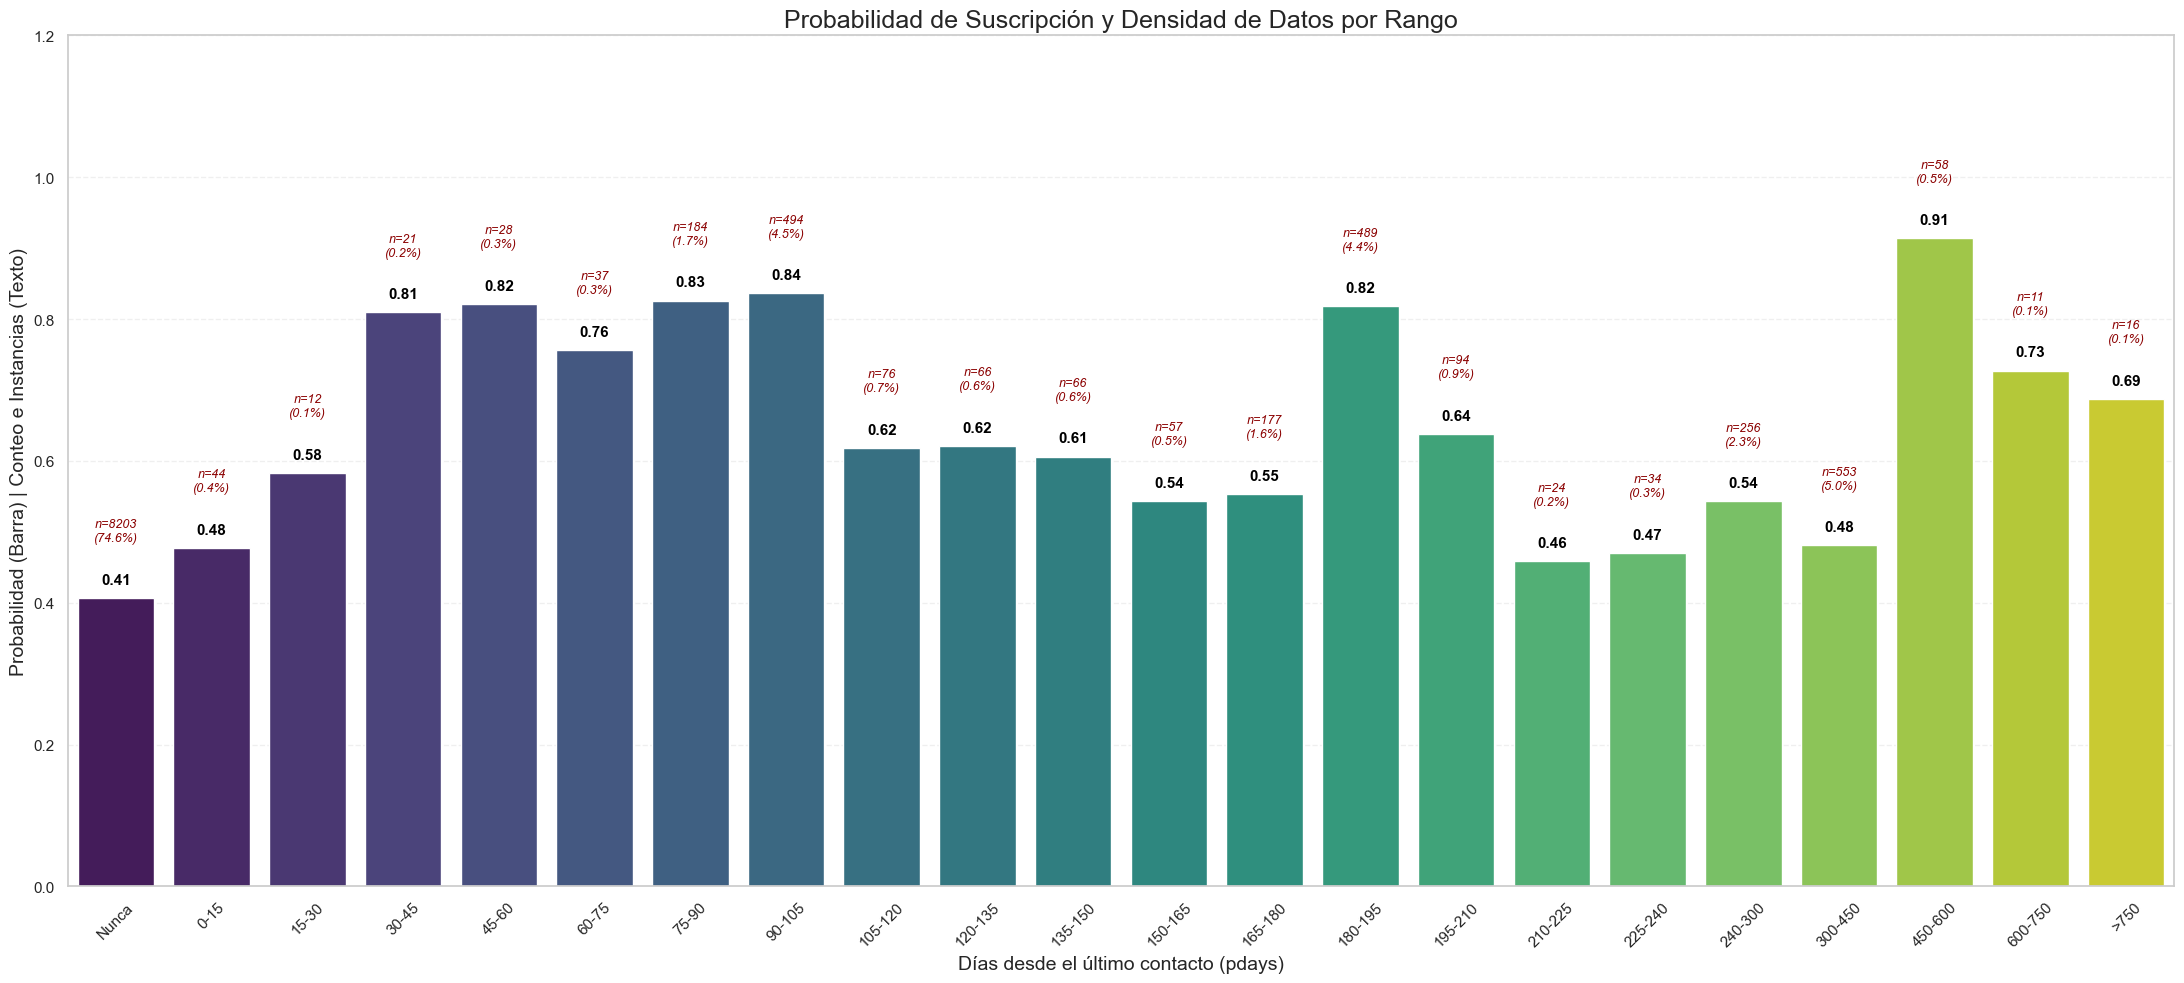

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Cargar los datos
df = pd.read_pickle("bank_09.pkl")

# Definir los cortes
max_val = df['pdays'].max()
bins = [-2, -1, 15, 30, 45, 60, 75, 90, 105, 120, 135, 150, 165, 180, 195, 210, 225, 240, 300, 450, 600, 750, max_val + 1]
labels = ['Nunca', '0-15', '15-30', '30-45', '45-60', '60-75', '75-90', '90-105', '105-120', '120-135', '135-150', '150-165', '165-180', '180-195', '195-210', '210-225', '225-240', '240-300', '300-450', '450-600', '600-750', '>750']

df['pdays_cat'] = pd.cut(df['pdays'], bins=bins, labels=labels)
df['target'] = df['deposit'].map({'yes': 1, 'no': 0})

# Calcular estadísticas por categoría
stats = df.groupby('pdays_cat', observed=False).agg(
    probabilidad=('target', 'mean'),
    conteo=('target', 'count')
).reset_index()

total_instancias = len(df)
stats['porcentaje'] = (stats['conteo'] / total_instancias) * 100

# Hacer el gráfico
plt.rcParams["figure.figsize"] = (22, 10)
ax = sns.barplot(x='pdays_cat', y='probabilidad', data=stats, palette='viridis')

plt.title('Probabilidad de Suscripción y Densidad de Datos por Rango', fontsize=18)
plt.xlabel('Días desde el último contacto (pdays)', fontsize=14)
plt.ylabel('Probabilidad (Barra) | Conteo e Instancias (Texto)', fontsize=14)
plt.xticks(rotation=45)
plt.ylim(0, 1.2)

for i, row in stats.iterrows():
    if not np.isnan(row['probabilidad']):
        # Texto de la probabilidad
        plt.text(i, row['probabilidad'] + 0.02, f"{row['probabilidad']:.2f}", 
                 ha='center', fontweight='bold', color='black', fontsize=11)
        # Texto del conteo y porcentaje debajo
        plt.text(i, row['probabilidad'] + 0.08, f"n={int(row['conteo'])}\n({row['porcentaje']:.1f}%)", 
                 ha='center', fontsize=9, color='darkred', fontstyle='italic')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

print(stats)

Tras comprobar el gráfico, descubrimos un efecto contrario a lo que dice el "Efecto memoria": la mayor probabilidad de subscripción del producto se da en los usuarios que llevan entre uno y dos meses sin ser contactados. En cambio, los que han sido contactados entre 30 y 105 días presentan una posibilidad mucho mayor de subscribir el producto. Lo mismo pasa con los no contactados desde entre 180 y 195 dias. Sin embargo, hay que tener cuidado con una cosa, los datos anómalos, esto se aprecia muy claramente en el rango '450-600', donde hay una probabilidad de suscripción del producto del 91%, la más alta de todas, sin embargo, solo hay 58 instancias disponibles, por lo que muy probablemente sea un dato anómalo.

Por lo tanto, tras considerar la gráfica y toda la información que esta nos da, creemos que los anteriores rangos no son los mejores, ya que no representan la realidad de forma fidedigna. En cambio, se proponen estos nuevos rangos:

0. Nunca contactado
1. Más de  210 días
2. 180 - 210 días
3. 105 - 180 días
4. 30 - 105 días
5. 0 - 30 días

In [8]:

# Usamos -2 para que el valor -1 entre en el primer bin
max_pdays = datos['pdays'].max()
bins = [-2, -1, 30, 105, 180, 210, max_pdays]

# Ordenamos del 0 al 5 (donde 5 es lo más reciente y 0 es nunca)
labels = [0, 5, 4, 3, 2, 1] 

datos['pdays'] = pd.cut(datos['pdays'], bins=bins, labels=labels).astype(int)

# Verificación de que no hemos perdido datos
print(datos['pdays'].value_counts(normalize=True).sort_index() * 100)

pdays
0    74.572727
1     8.654545
2     5.300000
3     4.018182
4     6.945455
5     0.509091
Name: proportion, dtype: float64


## 2. ¿Cómo se va a realizar la evaluación?

**2.1. Métrica adecuada para el problema y implementación del holdout**

Para la implementación del holdout aleatorio, nosotros haremos dos particiones para cumplir con los requisitos del enunciado: train (2/3) y test (1/3). Además, para asegurar la correcta distribución de los datos en las dos particiones, usaremos estratificación. Esto último no sería estrictamente necesario, pues la base de datos ya está practicamente balanceada, sin embargo, al utilizarlo, nos aseguramos de que en todos los casos posibles las particiones estén totalmente balanceadas.

En cuanto a la métrica, debido al casi perfecto balanceo de la variable deposit, consideramos que la principal métrica a optimizar será el accuracy, concretamente los modelos a implementar deberán superar un 52.5% de acierto (deposit tiene un 52,5% de noes). 

**2.2. División de los datos en train y test.**

Para la división de los datos, ejecutamos el siguiente código, que nos separará los datos en train y test usando estratificación. Además se incluye el NIA de uno de nosotros para asegurar la reproducibilidad.

In [33]:
from sklearn.model_selection import train_test_split

# Separamos las características de la variable objetivo
X = datos.drop('deposit', axis=1)
y = datos['deposit']

# Realizamos la partición Holdout
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=1/3, 
    stratify=y, 
    random_state=100522281
)

# Comprobación de las dimensiones y de la estratificación
print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}\n")

print("Distribución de la variable objetivo en TRAIN:")
print(y_train.value_counts(normalize=True) * 100)

print("\nDistribución de la variable objetivo en TEST:")
print(y_test.value_counts(normalize=True) * 100)

Dimensiones de X_train: (7333, 16)
Dimensiones de X_test: (3667, 16)

Distribución de la variable objetivo en TRAIN:
deposit
no     52.543297
yes    47.456703
Name: proportion, dtype: float64

Distribución de la variable objetivo en TEST:
deposit
no     52.549768
yes    47.450232
Name: proportion, dtype: float64


**2.3. Evaluación interna**

Para llevar a cabo la evaluación interna, que nos servirá para la optimización de hiperparámetros (HPO), utilizaremos Validación Cruzada Estratificada (Stratified K-Fold Cross-Validation) con 5 folds. Hemos decidido esto debido a que, bajo nuestro punto de vista, esta política es la que más posibilidades tiene de definir unos mejores hiperparámetros a pesar del coste computacional que supone la validación cruzada. 

El conjunto train se dividirá en 5 folds, a nuestro juicio el valor óptimo, ya que para cada iteración podremos contrastar con casi 1500 instancias, manteniendo un coste computacional relativamente razonable. Cabe resaltar que, al igual que en el holdout, aquí también se usará la estratificación para asegurar que cada uno de los cinco folds respete la proporción original de la variable objetivo.

## 3. Métodos básicos: KNN y Árboles

**3.1. Método de escalado para este problema.**

Con el siguiente código creamos un pipeline para evaluar los escaladores disponibles: MinMaxScaler, StandardScaler y RobustScaler. 

In [34]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Identificamos automáticamente qué columnas son numéricas y cuáles texto/categóricas
columnas_numericas = X_train.select_dtypes(include=['number']).columns
columnas_categoricas = X_train.select_dtypes(include=['object', 'category']).columns

# Definimos el modelo base de KNN
knn_base = KNeighborsClassifier()

# Diccionario con los escaladores a probar
escaladores = {
    "MinMaxScaler": MinMaxScaler(),
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler()
}

pipelines = {}

# Construimos un Pipeline para cada escalador integrando el ColumnTransformer
for nombre, escalador in escaladores.items():
    
    # El preprocesador separa el trato a números y a categorías
    preprocesador = ColumnTransformer(
        transformers=[
            ('num', escalador, columnas_numericas),
            ('cat', OneHotEncoder(handle_unknown='ignore'), columnas_categoricas)
        ],
        remainder='passthrough'
    )
    
    # Unimos el preprocesado y el modelo en el pipeline final
    pipelines[nombre] = Pipeline(steps=[
        ('preprocesador', preprocesador),
        ('knn', knn_base)
    ])

# Evaluación con validación cruzada
resultados_escalado = {}

for nombre, pipeline in pipelines.items():
    # k=5, accuracy como métrica y n_jobs=-1 para usar todos los núcleos
    scores = cross_val_score(
        pipeline, 
        X_train, 
        y_train, 
        cv=5, 
        scoring='accuracy', 
        n_jobs=-1
    )
    
    media_accuracy = np.mean(scores)
    resultados_escalado[nombre] = media_accuracy
    
    print(f"{nombre}: Accuracy medio = {media_accuracy:.4f} (Desviación: {np.std(scores):.4f})")

# Imprimimos el ganador
mejor_escalador = max(resultados_escalado, key=resultados_escalado.get)
print(f"\nEl mejor método de escalado para KNN es: {mejor_escalador}")

MinMaxScaler: Accuracy medio = 0.7271 (Desviación: 0.0054)
StandardScaler: Accuracy medio = 0.7991 (Desviación: 0.0078)
RobustScaler: Accuracy medio = 0.7971 (Desviación: 0.0045)

El mejor método de escalado para KNN es: StandardScaler


Tras evaluar los resultados obtenemos que el mejor escalador (por lo menos para knn) es standard scaler. 

**3.2. Estudio de KNN**

***a) Evaluación del método con parámetros por omisión***

Para ver qué accuracy tiene un modelo knn con los parámetros por defecto ejecutamos el siguiente código. Básicamente lo que hace es lo siguiente:

1. Primero realiza el preprocesado de la base de datos con ColumnTransformer, donde se aplica standardScaler o OneHotEncoder donde corresponda.
2. Construye el pipeline, donde se encadena el preprocesado anterior y el modelo. Se instancia KNeighborsClassifier sin argumentos, por los que usará los de por defecto. 
3. Se inicia el cross_validate y se mide el tiempo de ejecución del entrenamiento.
4. Se presentan los resultados.

In [35]:
import time
from sklearn.model_selection import cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.neighbors import KNeighborsClassifier


# Definimos las columnas numericas, categoricas y ordinales
columnas_numericas = X_train.select_dtypes(include=['number']).columns
todas_categoricas = X_train.select_dtypes(include=['object', 'category']).columns
columnas_ordinales = ['education']
columnas_categoricas_sin_education = todas_categoricas.drop(columnas_ordinales) # quitamos education de las columnas categóricas

# hacemos el pipeline Numerico
num_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()) # aplicamos el escalado para corregir las diferencias entre los valores
])

# hacemos el pipeline Categorico
cat_pipeline = Pipeline(steps=[
    ('imputer_none', SimpleImputer(missing_values=None, strategy='most_frequent')),       # Elimina los None
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), # Elimina los 'unknown'
    ('ohe', OneHotEncoder(handle_unknown='ignore')) # hacemos one-hot encoding
])

# hacemos el pipeline Ordinal
categorias_educacion = [['primary', 'secondary', 'tertiary']] 
ord_pipeline = Pipeline(steps=[
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), # Elimina los 'unknown'
    ('ordinal', OrdinalEncoder(categories=categorias_educacion, handle_unknown='use_encoded_value', unknown_value=-1))
])

# Ensamblamos el preprocesador definitivo separando los tres flujos
preprocesador_final = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, columnas_numericas),
        ('cat', cat_pipeline, columnas_categoricas_sin_education),
        #('ord', ord_pipeline, columnas_ordinales)
    ]
)

# Creamos el pipeline completo
pipeline_knn_defecto = Pipeline(steps=[
    ('preprocesador', preprocesador_final),
    ('knn', KNeighborsClassifier())
])

# Medimos el tiempo que tarda en entrenarse el modelo
inicio = time.time()
cv_resultados = cross_validate(
    pipeline_knn_defecto, 
    X_train, 
    y_train, 
    cv=5, 
    scoring='accuracy', 
    n_jobs=-1,
    return_train_score=False
)
fin = time.time()

# Cálculamos las métricas finales
accuracy_medio = cv_resultados['test_score'].mean()
tiempo_total = fin - inicio
tiempo_entrenamiento_medio = cv_resultados['fit_time'].mean()


print(f"--- Evaluación KNN con mejoras de preprocesado y k=5 ---")
print(f"Accuracy medio: {accuracy_medio:.4f}")
print(f"Tiempo medio de entrenamiento por fold: {tiempo_entrenamiento_medio:.4f} segundos")
print(f"Tiempo total del proceso (5 folds): {tiempo_total:.4f} segundos")

--- Evaluación KNN con mejoras de preprocesado y k=5 ---
Accuracy medio: 0.7948
Tiempo medio de entrenamiento por fold: 0.0179 segundos
Tiempo total del proceso (5 folds): 0.0827 segundos


Los resultados obtenidos tras la realización de este modelo son los siguientes:

- Podemos ver claramente una tasa de aciertos media del 79,48%, que la usaremos para comprobar si logramos mejorar la capacidad de generalizar del algoritmo tras optimizar los hiperparámetros.

- También podemos observar que el tiempo medio de entrenamiento por fold es muy bajo (0,0192 segundos), que tiene sentido ya que KNN es lazy y en la fase de Train solamente almacena los datos en memoria. Por ello el mayor esfuerzo computacional recae en la predicción, lo que justifica que el tiempo total de proceso para 5 folds ascienda a 0,0812 segundos.

- Una cosa importante que hay que señalar es que las líneas de código relacionadas con la columna ordinal 'education' se han comentado debido a que aunque esa variable la habíamos clasificado como ordinal, al final el resultado ha mejorado tras considerarla como una variable categórica más.

***b) Ajuste de hiperparámetros***

Para la optimización del algoritmo KNN, nos hemos centrado en el hiperparámetro K (vecinos más cercanos), ya que es el que mayor impacto tiene en la capacidad de generalización y en el control del overfitting.

En cuanto al hiperparámetro p (métrica de distancia), hemos decicido mantenerlo por defecto (Distancia Euclídea) para simplificar el espacio de búsqueda.

Para ajustar los hiperparámetros hemos decidido utilizar la técnica de GridSearchCV en lugar de RandomizedSearchCV. Consideramos que al tener un único hiperparámetro a optimizar (K), habrá que explorar un número de combinaciones reducido, y GridSearch nos garantiza encontrar el valor óptimo exacto. En cambio RandomizedSearchCV está diseñado para analizar múltiples hiperparámetros a la vez.

Para ello utilizaremos una rejilla de valores impares para evitar empates en la clasificación (desde K=1 hasta K=30).


In [40]:
from sklearn.model_selection import GridSearchCV
import time

# Definimos el espacio de búsqueda (la rejilla)
param_grid_knn = { # Probamos varios valores de K para encontrar el óptimo
    'knn__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 20, 25, 30], 
    'knn__weights': ['uniform', 'distance'] 
}

# Configuramos la herramienta GridSearchCV
grid_knn = GridSearchCV(
    estimator=pipeline_knn_defecto,
    param_grid=param_grid_knn,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# Entrenamos el modelo probando todas las combinaciones y medimos el tiempo de búsqueda
inicio_grid = time.time()

# Probamos cada 5 veces (por el cv=5)
grid_knn.fit(X_train, y_train)

fin_grid = time.time()

tiempo_total_grid = fin_grid - inicio_grid

# Extraemos el tiempo de entrenamiento específico del mejor modelo
# Buscamos en qué posición quedó el ganador
indice_mejor = grid_knn.best_index_

# Sacamos su tiempo medio de entrenamiento (fit_time)
tiempo_entrenamiento_mejor = grid_knn.cv_results_['mean_fit_time'][indice_mejor]

# Extraemos y mostramos los mejores resultados
print(f"--- Resultados de GridSearchCV para KNN ---")
print(f"Mejor valor de K encontrado: {grid_knn.best_params_}")
print(f"Accuracy medio con el mejor K: {grid_knn.best_score_:.4f}")
print(f"Tiempo medio de entrenamiento por fold (con el mejor K): {tiempo_entrenamiento_mejor:.4f} segundos")
print(f"Tiempo total de entrenamiento con HPO: {tiempo_total_grid:.4f} segundos")

--- Resultados de GridSearchCV para KNN ---
Mejor valor de K encontrado: {'knn__n_neighbors': 20, 'knn__weights': 'distance'}
Accuracy medio con el mejor K: 0.8055
Tiempo medio de entrenamiento por fold (con el mejor K): 0.0217 segundos
Tiempo total de entrenamiento con HPO: 0.7019 segundos


Tras aplicar la búsqueda con GridSearchCV, el mejor valor encontrado para el número de vecinos ha sido K=20 y el hiperparámetro 'distance', haciendo que el modelo tenga una tasa de aciertos media del 80,55%, lo que supone una mejora comparada con el modelo con los parámetros por defecto. Esto demuestra que tener en cuenta más vecinos hace que el modelo generalice mejor y evite el ruido local (evitando así el overfitting que se produce con valores de K muy bajos). Además también evidencia que el modelo trabaja mejor dando más peso a los vecinos más cercanos en vez de a todos por igual.

Hemos querido analizar dos tiempos, por un lado el tiempo medio de entrenamiento por fold para nuestro modelo óptimo (k=20) que se mantiene igual de bajo que el modelo base (sin HPO). No podía cambiar mucho ya que KNN sigue siendo un algoritmo perezoso, este tiempo no va a variar mucho independientemente del valor dado a la K.

Por otro lado tenemos el tiempo total de entrenamiento con HPO, que ha pasado de 0,0812 (en el anterior modelo) a 0,7020 segundos. Es el tiempo que esperábamos que saliese, ya que en este modelo se han realizado 50 ciclos de Entrenamiento y Evaluación (10 valores de K evaluados en 5 folds) seguido de un reentrenamiento del modelo con el 100% de los datos de Entrenamiento

***c) Análisis mediante Plots de los valores que pueden tener los hiperparámetros de KNN***

Vamos a ver el impacto en el accuracy de los posibles valores de K mediante una gráfica.

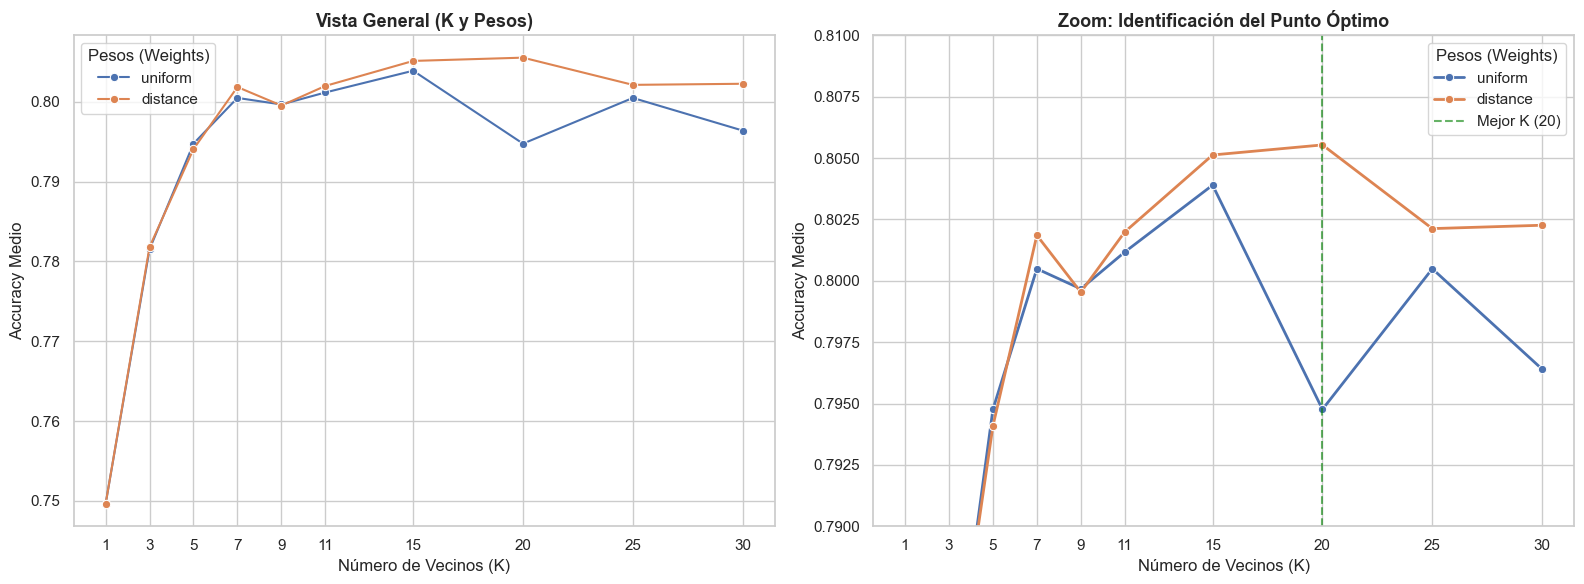

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convertimos todos los resultados de la búsqueda a un DataFrame
resultados_df = pd.DataFrame(grid_knn.cv_results_)

# Extraemos los valores del grid original y el mejor K automáticamente 
valores_k = param_grid_knn['knn__n_neighbors']
mejor_k = grid_knn.best_params_['knn__n_neighbors']

# Creamos una figura con dos subgráficos (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Grafico 1, vista general con escala amplia
# Usamos 'hue' para separar por tipo de peso (uniform vs distance)
sns.lineplot(
    data=resultados_df, 
    x='param_knn__n_neighbors', 
    y='mean_test_score', 
    hue='param_knn__weights', 
    marker='o', 
    ax=ax1
)
ax1.set_title('Vista General (K y Pesos)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Número de Vecinos (K)')
ax1.set_ylabel('Accuracy Medio')
ax1.set_xticks(valores_k)

# Gráfico 2: Vista detallada (zoom al pico)
sns.lineplot(
    data=resultados_df, 
    x='param_knn__n_neighbors', 
    y='mean_test_score', 
    hue='param_knn__weights', 
    marker='o', 
    linewidth=2,
    ax=ax2
)
ax2.set_title('Zoom: Identificación del Punto Óptimo', fontsize=13, fontweight='bold')
ax2.set_xlabel('Número de Vecinos (K)')
ax2.set_ylabel('Accuracy Medio')
ax2.set_xticks(valores_k)
ax2.set_ylim(0.79, 0.81) 

# Línea vertical dinámica en el mejor K encontrado
ax2.axvline(x=mejor_k, color='green', linestyle='--', alpha=0.6, label=f'Mejor K ({mejor_k})')

# Ajustamos las leyendas para que queden limpias
ax1.legend(title='Pesos (Weights)')
ax2.legend(title='Pesos (Weights)')

plt.tight_layout()
plt.show()

Para analizar el impacto del hiperparámetro K y distance, hemos representado los resultados a dos escalas. En la gráfica de la izquierda se observa la evolución general, donde se aprecia cómo el modelo estabiliza su comportamiento rápidamente. En la gráfica de la derecha aplicamos un zoom sobre el rango de mayor precisión para identificar con claridad el pico de rendimiento en K=20.

Gracias a la curva generada podemos concluir que:

- Valores bajos: K < 7: con valores muy bajos de vecinos el modelo presenta una tasa de acierto inferior. Esto se debe al overfitting ya que el algoritmo es muy sensible al ruido y a los casos particulares de los datos de Entrenamiento, creando fronteras demasiado complejas que no funcionan bien con datos nuevos.

- Punto óptimo: K = 20: es el valor que maximiza la capacidad de generalización. El número de vecinos que se comprueba es lo suficientemente grande para filtrar anomalías, pero lo bastante acotado para capturar correctamente los patrones locales de los datos sin diluirlos en la tendencia global o "mayoría" del dataset.

- Valores altos: K > 20: a medida que aumentamos el número de vecinos el accuracy empieza a caer ligeramente, mostrando underfitting. Al considerar demasiados vecinos, el modelo se vuelve demasiado simple y tiende a ignorar patrones locales y a predecir basándose simplemente en la mayoría global.

**3.3. Estudio de Árboles de Decisión**

***a) Evaluación del método con parámetros por omisión***

Al igual que hicimos con KNN, primero evaluaremos el modelo de Árboles de Decisión con sus hiperparámetros por defecto. 
A diferencia de KNN, los Árboles de Decisión no calculan distancias geométricas, por lo que son inmunes a la diferencia de escalas entre variables y no necesitan que los datos numéricos fuesen escalados o normalizados previamente


In [43]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Nos aseguramos de capturar todas las columnas correctamente antes de empezar
columnas_numericas = X_train.select_dtypes(include=['number']).columns
columnas_categoricas = X_train.select_dtypes(include=['object', 'category']).columns

# Pipeline categórico
cat_pipeline_arbol = Pipeline(steps=[
    ('imputer_none', SimpleImputer(missing_values=None, strategy='most_frequent')),       # Elimina los None
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), # Elimina los 'unknown'
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

# no hace falta hacer un pipeline ordinal ni numerico porque los arboles son modelos que no entienden de distancias

# Preprocesador
preprocesador_arbol = ColumnTransformer(
    transformers=[
        ('cat', cat_pipeline_arbol, columnas_categoricas),
        ('num', 'passthrough', columnas_numericas) # Dejamos pasar las numéricas explícitamente
    ],
    remainder='drop' # Si se nos olvida alguna columna, la descarta en lugar de romper el código
)

# Creamos el pipeline con el Árbol por defecto
pipeline_arbol_defecto = Pipeline(steps=[
    ('preprocesador', preprocesador_arbol),
    ('arbol', DecisionTreeClassifier(random_state=100522281)) 
])

cv_outer = KFold(n_splits=5, shuffle=True, random_state=100522281)

# Evaluación y medida de tiempos
inicio_arbol = time.time()
cv_resultados_arbol = cross_validate(
    pipeline_arbol_defecto, 
    X_train, 
    y_train, 
    cv=cv_outer, 
    scoring='accuracy', 
    n_jobs=-1
)
fin_arbol = time.time()

# Cálculo de métricas finales
accuracy_medio_arbol = cv_resultados_arbol['test_score'].mean()
tiempo_total_arbol = fin_arbol - inicio_arbol
tiempo_entrenamiento_medio_arbol = cv_resultados_arbol['fit_time'].mean()

print(f"--- Evaluación Árbol de Decisión con parámetros por defecto ---")
print(f"Accuracy medio: {accuracy_medio_arbol:.4f}")
print(f"Tiempo medio de entrenamiento por fold: {tiempo_entrenamiento_medio_arbol:.4f} segundos")
print(f"Tiempo total del proceso (5 folds): {tiempo_total_arbol:.4f} segundos")

--- Evaluación Árbol de Decisión con parámetros por defecto ---
Accuracy medio: 0.7709
Tiempo medio de entrenamiento por fold: 0.0399 segundos
Tiempo total del proceso (5 folds): 0.8930 segundos


Para poder ver la razón de nuestros resultados, querremos ver cuáles son los hiperparámetros por defecto. Los principales, y los que vamos a tener nosotros en cuenta son criterion, max_depth y min_samples_split.

In [15]:
from sklearn.tree import DecisionTreeClassifier

arbol_prueba = DecisionTreeClassifier(random_state=100522287)
arbol_prueba.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 100522287,
 'splitter': 'best'}

***b) Ajuste de Hiperparámetros***

A continuación, como hemos visto anteriormente, optimizaremos los hiperparámetros clave del Árbol de Decisión para controlar su complejidad y evitar que crezca en exceso:

- criterion[gini, entropy]: evaluamos las dos funciones matemáticas disponibles para medir la calidad de una división de nodo. Gini mide la impureza, mientras que la Entropía calcula la ganancia de información. Aunque en la práctica suelen tener resultados similares, probar ambos nos asegura obtener el mejor ajuste posible según la distribución exacta de nuestras características.

- max_depth[rango del 2 al 20, en saltos de 2]: es el hiperparámetro más crítico para evitar el overfitting. 
    - Omitimos la profundidad 1 (stumps) por ser modelos demasiado simples que causan un claro underfitting. 
    - Acotamos el límite superior a 20 para evitar el crecimiento exponencial del árbol (que podría generar decenas de miles de hojas), impidiendo así que memorice clientes individuales o ruido estadístico. 
    * Utilizar saltos de 2 en 2 (range(2, 20, 2)) nos permite explorar todo el espectro de complejidad ahorrando mucho tiempo de computación.

- min_samples_split[rango del 2 al 50, en saltos de 2]: actúa como un criterio de parada local. El valor por defecto (2) es muy propenso al sobreajuste, ya que permite aislar a clientes casi de uno en uno. Al exigir que un nodo tenga hasta 14 muestras para poder seguir dividiéndose, forzamos al algoritmo a crear ramas más robustas y reglas de decisión estadísticamente más fiables y generalizables.

Aunque la optimización de múltiples hiperparámetros suele ser terreno de RandomizedSearchCV, el espacio de búsqueda definido aquí es lo suficientemente acotado como para que GridSearchCV sea computacionalmente viable, garantizando encontrar el óptimo global de la cuadrícula en pocos segundos.

Los resultados obtenidos muestran el rendimiento base del árbol. Normalmente, un árbol de decisión sin restricciones hace que crezca hasta que las hojas son puras y tiende a sufrir de overfitting. Aprende de memoria los datos de entrenamiento, incluyendo el ruido, pero pierde capacidad de generalización con datos nuevos. 

Al observar los resultados obtenidos por el árbol de decisión con sus parámetros por defecto, destacan dos aspectos fundamentales:

- Tiempos de ejecución: Los tiempos de procesamiento han resultado ser superiores a los obtenidos inicialmente con KNN. Esto se debe al esfuerzo computacional de la fase de Entrenamiento, al no ponerle límites de profundidad al árbol (max_depth=None), y tener un dataset ensanchado por la codificación de variables categóricas (One-Hot Encoding), el algoritmo invierte una gran cantidad de tiempo buscando divisiones hasta conseguir que todas las hojas finales sean totalmente puras.

- Accuracy: El accuracy medio obtenido en los pliegues de validación representa nuestro rendimiento base. Como era de esperar, un árbol sin restricciones de crecimiento provoca un fuerte overfitting. Se aprende de memoria el dataset de entrenamiento (incluyendo el ruido) lo que limita enormemente su capacidad de generalización frente a datos nuevos.

Para solucionar este sobreajuste base y mejorar la tasa de acierto del modelo final procederemos a podar el árbol limitando su crecimiento mediante el ajuste de hiperparámetros.

In [44]:
# Definimos el espacio de búsqueda para el Árbol
param_grid_arbol = {
    'arbol__criterion': ['gini', 'entropy'],
    'arbol__max_depth': list(range(2, 20, 2)),
    'arbol__min_samples_split': list(range(2, 50, 2))
}

cv_inner = KFold(n_splits=5, shuffle=True, random_state=100522281)

# Configuramos GridSearchCV
grid_arbol = GridSearchCV(
    estimator=pipeline_arbol_defecto,
    param_grid=param_grid_arbol,
    scoring='accuracy',
    cv=cv_inner,
    n_jobs=-1,
    verbose=1
)
np.random.seed(100522281)

# Entrenamos el modelo probando las combinaciones
inicio_grid_arbol = time.time()
grid_arbol.fit(X_train, y_train)
fin_grid_arbol = time.time()

tiempo_total_grid_arbol = fin_grid_arbol - inicio_grid_arbol
indice_mejor_arbol = grid_arbol.best_index_
tiempo_entrenamiento_mejor_arbol = grid_arbol.cv_results_['mean_fit_time'][indice_mejor_arbol]

print(f"--- Resultados de GridSearchCV para Árbol de Decisión ---")
print(f"Mejores hiperparámetros encontrados: {grid_arbol.best_params_}")
print(f"Accuracy medio con el mejor modelo: {grid_arbol.best_score_:.4f}")
print(f"Tiempo medio de entrenamiento por fold: {tiempo_entrenamiento_mejor_arbol:.4f} segundos")
print(f"Tiempo total de entrenamiento con HPO: {tiempo_total_grid_arbol:.4f} segundos")

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
--- Resultados de GridSearchCV para Árbol de Decisión ---
Mejores hiperparámetros encontrados: {'arbol__criterion': 'entropy', 'arbol__max_depth': 14, 'arbol__min_samples_split': 48}
Accuracy medio con el mejor modelo: 0.8152
Tiempo medio de entrenamiento por fold: 0.0423 segundos
Tiempo total de entrenamiento con HPO: 10.3507 segundos


Tras ejecutar la búsqueda exhaustiva con GridSearchCV podemos extraer las siguientes conclusiones sobre el comportamiento del modelo:

- El mejor modelo utiliza el criterio Entropy (basado en la impureza del nodo), una profundidad máxima (max_depth) de 14 y requiere al menos 48 muestras (min_samples_split) para seguir dividiendo un nodo. Esta configuración confirma que un árbol necesita crecer lo suficiente para captar patrones (profundidad 14), pero necesita un freno (exigir 48 clientes juntos) para no crear ramas terminales que sistemáticamente memoricen casos atípicos o ruido (overfitting).

- Con esta configuración acotada, logramos un accuracy medio del 81,52% en los pliegues de validación. Al haber limitado la complejidad del árbol, podemos confiar en que esta métrica representa una capacidad de generalización real y robusta frente a datos nunca antes vistos, al contrario de lo que ocurría con el modelo base.

- Limitar el crecimiento del árbol no solo mejora el rendimiento predictivo, sino que tiene un impacto en los tiempos. El tiempo medio de entrenamiento por fold ha bajado a 0.0423 segundos, permitiendo que toda la malla de búsqueda (evaluando decenas de combinaciones) finalice en unos 10 segundos. Esto demuestra la eficiencia algorítmica de los árboles de decisión cuando no se les permite crecer hasta el infinito.

***c) Análisis mediante Plots de los valores que pueden tener los hiperparámetros de Árboles***

Vamos a ver el impacto en el accuracy de los posibles valores de los distintos hiperparámetros mediante una gráfica.

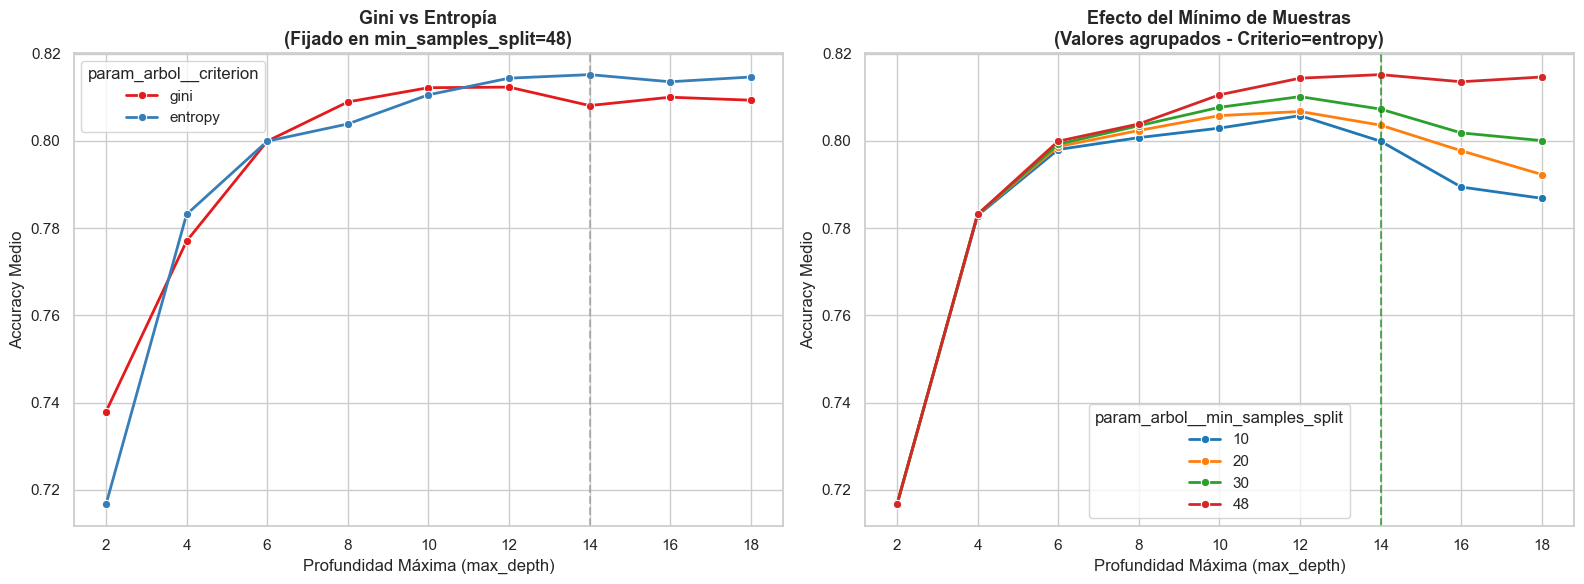

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convertimos los resultados de GridSearchCV a DataFrame
resultados_arbol_df = pd.DataFrame(grid_arbol.cv_results_)

# Extraemos los parámetros ganadores
mejor_depth = grid_arbol.best_params_['arbol__max_depth']
mejor_criterio = grid_arbol.best_params_['arbol__criterion']
mejor_split = grid_arbol.best_params_['arbol__min_samples_split']
profundidades = param_grid_arbol['arbol__max_depth']

# Filtramos los datos para aislar los efectos en cada gráfico
# Para el gráfico 1: Fijamos el split óptimo y comparamos los dos criterios
datos_criterios = resultados_arbol_df[resultados_arbol_df['param_arbol__min_samples_split'] == mejor_split]

# Para el gráfico 2: Fijamos el criterio óptimo y comparamos los distintos splits
datos_splits = resultados_arbol_df[resultados_arbol_df['param_arbol__criterion'] == mejor_criterio]

# Creamos la figura con los dos subgráficos independientes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# --- GRÁFICO 1: Gini vs Entropía ---
sns.lineplot(
    data=datos_criterios, 
    x='param_arbol__max_depth', 
    y='mean_test_score', 
    hue='param_arbol__criterion', 
    palette='Set1', # Paleta distinta para diferenciar visualmente del otro gráfico
    marker='o', 
    linewidth=2,
    ax=ax1
)
ax1.set_title(f'Gini vs Entropía\n(Fijado en min_samples_split={mejor_split})', fontsize=13, fontweight='bold')
ax1.set_xlabel('Profundidad Máxima (max_depth)')
ax1.set_ylabel('Accuracy Medio')
ax1.set_xticks(profundidades)
ax1.axvline(x=mejor_depth, color='gray', linestyle='--', alpha=0.5)

# --- GRÁFICO 2: Profundidad vs Mínimo de Muestras ---
valores_a_pintar = [5, 10, 15, 20, 25, 30] 

# Opcional: Si quieres asegurarte de que el mejor valor siempre se pinte aunque no acabe en 5:
if mejor_split not in valores_a_pintar:
    valores_a_pintar.append(mejor_split)

# 2. Filtramos la tabla para que solo contenga esos valores específicos
datos_splits_filtrados = datos_splits[datos_splits['param_arbol__min_samples_split'].isin(valores_a_pintar)]

# --- GRÁFICO 2: Profundidad vs Mínimo de Muestras (FILTRADO) ---
sns.lineplot(
    data=datos_splits_filtrados, # Usamos la tabla filtrada en lugar de la original
    x='param_arbol__max_depth', 
    y='mean_test_score', 
    hue='param_arbol__min_samples_split',
    palette='tab10',
    marker='o', 
    linewidth=2,
    ax=ax2
)
ax2.set_title(f'Efecto del Mínimo de Muestras\n(Valores agrupados - Criterio={mejor_criterio})', fontsize=13, fontweight='bold')
ax2.set_xlabel('Profundidad Máxima (max_depth)')
ax2.set_ylabel('Accuracy Medio')
ax2.set_xticks(profundidades)
ax2.axvline(x=mejor_depth, color='green', linestyle='--', alpha=0.6, label=f'Mejor Combinación')

plt.tight_layout()
plt.show()

Para analizar el impacto de los hiperparámetros max_depth (profundidad), min_samples_split (mínimo de muestras) y el criterio de partición, hemos representado los resultados en dos gráficas. En la gráfica de la izquierda se observa la comparativa entre los criterios Gini y Entropía. En la gráfica de la derecha analizamos cómo la profundidad del árbol interactúa con las distintas exigencias de agrupación para evitar el sobreajuste.

Gracias a las curvas generadas podemos concluir que:

- Valores bajos (max_depth < 6): con valores muy bajos de profundidad el modelo presenta una tasa de acierto notablemente inferior. Esto se debe al underfitting (subajuste), ya que el árbol es demasiado simple, tiene muy pocas ramas y no cuenta con la capacidad suficiente para aprender las reglas subyacentes ni separar adecuadamente los distintos perfiles de clientes.

- Punto óptimo (max_depth en torno a 14 y min_samples_split moderado alrededor de 48): es la combinación que maximiza la capacidad de generalización. El árbol tiene la profundidad suficiente para capturar correctamente los patrones de los datos, pero el límite de muestras exigido para dividir un nodo actúa como freno. Esto impide que el algoritmo cree reglas hiperespecíficas basadas en anomalías o casos aislados.

- Valores altos (max_depth > 14): en este escenario observamos una estabilización del accuracy de los distintos modelos, con una pequeña tendencia a la baja, pero sin grandes caídas.

- Criterio de partición: la diferencia de rendimiento entre usar la métrica matemática de Gini frente a la de Entropía es marginal en las zonas de mayor precisión, aunque si es cierto que gana Entropy. Esto demuestra que el control de la estructura geométrica del árbol (su tamaño y ramificación) es un factor mucho más determinante para el éxito del modelo que la fórmula utilizada para calcular la pureza de los nodos.

**3.4. Conclusiones de los modelos básicos**

Tras evaluar los distintos modelos básicos, tanto con sus hiperparámetros por defecto como usando HPO para encontrar los mejores, encontramos varias conclusiones interesantes:

- De todos ellos, podemos afirmar que el modelo más preciso es el del árbol con sus hiperparámetrso ajustados, ya que obtiene un accuracy del 81,52%, seguido de KNN con los hiperparámetros ajustados, con un 80,55%. Curiosamente, de los modelos con los hiperparámetros por defecto, KNN obtiene un resultado mejor que el árbol de decisión, a pesar de tener un coste computacional menor.

- En cuanto a coste computacional se refiere, el modelo con el mayor es el del árbol de decisión con los hiperparámetros ajustados, tardando unos 10 segundos, mucho más que su equivalente en KNN, que no llega al segundo. Por lo tanto, si el coste computacional es importante, el que más da por menos es el de KNN, aunque los 10 segundos del árbol, en la práctica, sean totalmente asumibles. En cuanto a los otros dos, ninguno de ellos llega al segundo, pero, de nuevo, KNN es más rapido que el árbol de decisión por milésimas de segundo.

- Todos los modelos superan con claridad los modelos dummy, ya que estos predicen la clase mayoritaria del dataset, en el caso que nos concierne la clase "no" con un 52,5%, y ninguno de los modelos desarrollados obtienen menos de un 77% de accuracy, por lo que se puede afirmar que están aprendiendo patrones útiles para poder generalizar e inferir correctamente.

- Tanto en KNN como en árboles, el ajuste de hiperparámetros mejora claramente ambos modelos, pasando de un accuracy de un 79,48% a un 80,55%, y de un 77,09% a un 81,52% en árboles. En cuanto a coste computacional, al hacer ajuste de hiperparámetros aumenta el tiempo de entrenamiento en ambos modelos, sin embargo, porcentualemtne, en árboles aumenta muchísimo más, debido a la gran cantidad de modelos que hay que probar.

## 4. Métodos avanzados: Modelos lineales y SVM

**4.1. Modelos lineales**

Debido a que es un problema de clasificacíon binaria, de los modelos lienales sólo tiene sentido detenerse en la regresión logística, pues es el único de todos los modelos lineales especializado en problemas de clasificación.

***a) Evaluación del método con parámetros por omisión***

Al igual que en el resto del proyecto, lo primero que se evaluará será el modelo (en este caso regresión logística) con sus hiperparámetros por defecto y haciendo todo el preprocesado. 

Para ello primero se tratarán las variables numéricas, aplicando un escalado a todas las variables, fundamental precisamente para este tipo de modelos, porque si no se hicierse así el algoritmo daría muchisimo más peso a coeficientes altos, y también una imputación de los valores faltantes.

A las variables categóricas se le realizará una imputación de los valores faltantes y luego un OneHotEncoder, ya que este tipo de modelos solo trata con números.

In [47]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression

# Definimos las columnas
columnas_numericas = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
columnas_ordinales = ['education']
columnas_categoricas_nominales = ['job', 'marital', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

# pipeline numerico
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# pipeline categorico
cat_pipeline = Pipeline(steps=[
    ('imputer_none', SimpleImputer(missing_values=None, strategy='most_frequent')),       # Elimina los None
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), # Elimina los 'unknown'
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

# pipeline ordinal
categorias_educacion = [['primary', 'secondary', 'tertiary']] 
ord_pipeline = Pipeline(steps=[
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), # Elimina los 'unknown'
    ('ordinal', OrdinalEncoder(categories=categorias_educacion, handle_unknown='use_encoded_value', unknown_value=-1))
])

# pipeline del preprocesado
preprocesador_logreg = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, columnas_numericas),
        ('cat', cat_pipeline, columnas_categoricas_nominales),
        ('ord', ord_pipeline, columnas_ordinales)
    ], 
    remainder= 'drop'
)

# pipeline final con modelo
pipeline_logreg = Pipeline(steps=[
    ('preprocesador', preprocesador_logreg),
    ('logreg', LogisticRegression(random_state= 100522281))
])

# definimos cv
cv_outer = KFold(n_splits=5, shuffle=True, random_state=100522281)

# entrenamos el modelo
inicio = time.time()
cv_resultados_logreg = cross_validate(
    pipeline_logreg,
    X_train,
    y_train, 
    cv= cv_outer,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
fin = time.time()


# Calculamos y mostramos métricas
accuracy_medio_logreg = cv_resultados_logreg['test_score'].mean()
tiempo_total_logreg = fin - inicio

print(f"--- Evaluación Regresión Logística con parámetros por defecto ---")
print(f"Accuracy medio: {accuracy_medio_logreg:.4f}")
print(f"Tiempo total del proceso (5 folds): {tiempo_total_logreg:.4f} segundos")



[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.


--- Evaluación Regresión Logística con parámetros por defecto ---
Accuracy medio: 0.8119
Tiempo total del proceso (5 folds): 0.8636 segundos


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    0.9s finished


Estos resultados son reveladores, pues hasta ahora este modelo ha conseguido la mejor puntuación de todos los desarrollados, superando a los árboles con HPO, pero con un coste computacional infinitamente menor, ya que no llega siquiera al segundo el tiempo necesario para ser entrenado.

***b) Evaluación del método con ajuste de hiperparámetros***

Para obetener aún un mejor resultado con este modelo, nos disponemos al ajuste de sus hiperparámetros, tenemos tres principalmente:

- C: Es posiblemente el hiperparámetro más importante, ya que controla la complejidad del modelo. Es el inverso de la fuerza de regularización.

- penalty: Hiperparámetro que dicta con qué algoritmo penalizamos los pesos, hay tres: L1, L2 y ElasticNet

- solver: Especifica el método para resolver la ecuación w * x + b

In [ ]:
import warnings
warnings.filterwarnings('ignore') # añadimos esto debido a que en este modelo salen muchos warnings innecesarios (Convergencewarnings)

# Definimos todos los posibles hiperparámetros
# lo dividimos en varios bloques ya que hay hiperparametros que son incompatibles entre si
param_grid_logreg = [
    # Para liblinear (soporta l1 y l2)
    {
        'logreg__solver': ['liblinear'],
        'logreg__penalty': ['l1', 'l2'],
        'logreg__C': [0.01, 0.1, 1, 10, 100],
        'logreg__max_iter': [50, 100, 500, 1000]
    },
    
    # Para lbfgs (solo soporta l2)
    {
        'logreg__solver': ['lbfgs'],
        'logreg__penalty': ['l2'],
        'logreg__C': [0.01, 0.1, 1, 10, 100],
        'logreg__max_iter': [50, 100, 500, 1000]
    },
    
    # Para saga con elasticnet (exige el l1_ratio)
    {
        'logreg__solver': ['saga'],
        'logreg__penalty': ['elasticnet'],
        'logreg__C': [0.01, 0.1, 1, 10, 100],
        'logreg__l1_ratio': [0.2, 0.5, 0.8],
        'logreg__max_iter': [50, 100, 500, 1000]
    }
]

# definimos el cv
cv_inner = KFold(n_splits=5, shuffle=True, random_state=100522281)

# Configuramos gridsearch
grid_logreg = GridSearchCV(
    estimator= pipeline_logreg,
    param_grid= param_grid_logreg,
    scoring= 'accuracy',
    cv= cv_inner,
    n_jobs=-1,
    verbose=1
)

# Ejecutamos la búsqueda y medimos el tiempo
print("Iniciando ajuste de hiperparámetros para Regresión Logística...")
inicio_grid = time.time()

# Entrenamos probando todas las combinaciones
grid_logreg.fit(X_train, y_train)

fin_grid = time.time()

# Calculamos y mostramos los resultados finales
print("\n--- Resultados de la Optimización (HPO) ---")
print(f"Mejor combinación de hiperparámetros:\n{grid_logreg.best_params_}")
print(f"Mejor accuracy en validación cruzada: {grid_logreg.best_score_:.4f}")
print(f"Tiempo total del proceso: {fin_grid - inicio_grid:.4f} segundos")



Iniciando ajuste de hiperparámetros para Regresión Logística...
Fitting 5 folds for each of 120 candidates, totalling 600 fits

--- Resultados de la Optimización (HPO) ---
Mejor combinación de hiperparámetros:
{'logreg__C': 0.1, 'logreg__max_iter': 100, 'logreg__penalty': 'l2', 'logreg__solver': 'lbfgs'}
Mejor accuracy en validación cruzada: 0.8136
Tiempo total del proceso: 14.7352 segundos


Tras entrenar el modelo, obtenemos unos resultados interesantes:

- C: El más óptimo es C=0.1, un valor relativamente pequeño, que hace que la regularización sea fuerte, por lo que el modelo decide ser menos sensible al ruido de los datos de entrenamiento para poder generalizar mejor.

- Penalty: El modelo ha elegido Ridge. Esto significa que está penalizando los coeficientes muy grandes para evitar que una sola variable domine sobre las demás.

- max_iter: El más óptimo es 100. Esto significa que el modelo alcanza su mejor capacidad de generalización antes de profundizar demasiado en los datos de entrenamiento. Este fenómeno se conoce como "Early Stopping" y hace que el modelo sea más rápido y mejor ante datos nuevos.

- Solver: lbfgs. Ha elegido este solver porque es el algoritmo de estabilización por defecto y maneja muy bien la penalizacion Ridge.

- En cuanto al accuracy obtenido, notamos que, aunque ha mejorado, la mejoría (+0,17%) no corresponde al aumento del tiempo del proceso de entrenamiento total del modelo. De esto podemos concluir que la configuración por defecto del modelo es bastante buena, pues como se podrá ver en la gráfica posterior, el modelo se estabiliza con esa configuración, resultando en cambios extremadamente pequeños de ahí en adelante.

***c) Análisis mediante Plots de los valores que pueden tener los hiperparámetros de regresión logística***

Vamos a ver el impacto en el accuracy de los posibles valores de los distintos hiperparámetros mediante una gráfica.

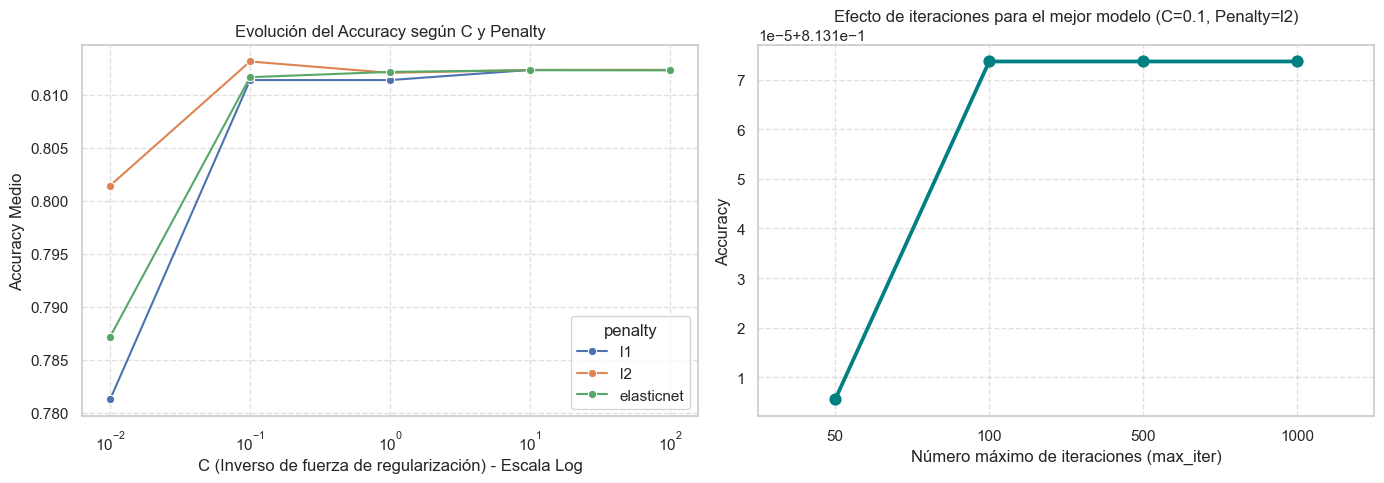

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extraemos los resultados del GridSearch y los convertimos en un DataFrame
resultados_grid = pd.DataFrame(grid_logreg.cv_results_)

# 2. Limpiamos los nombres de las columnas para facilitar la visualización
resultados_grid['C'] = resultados_grid['param_logreg__C'].astype(float)
resultados_grid['max_iter'] = resultados_grid['param_logreg__max_iter'].astype(int)
resultados_grid['penalty'] = resultados_grid['param_logreg__penalty'].astype(str)
resultados_grid['Accuracy'] = resultados_grid['mean_test_score']

# NUEVO: Extraemos cuáles fueron los mejores parámetros para aislar el caso de éxito
mejor_C = grid_logreg.best_params_['logreg__C']
mejor_penalty = grid_logreg.best_params_['logreg__penalty']

# 3. Configuramos el lienzo para poner dos gráficas lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- GRÁFICA 1: Efecto de 'C' y el tipo de penalización ---
sns.lineplot(
    data=resultados_grid, 
    x='C', 
    y='Accuracy', 
    hue='penalty', 
    marker='o', 
    errorbar=None, 
    ax=axes[0]
)
axes[0].set_xscale('log')
axes[0].set_title('Evolución del Accuracy según C y Penalty')
axes[0].set_xlabel('C (Inverso de fuerza de regularización) - Escala Log')
axes[0].set_ylabel('Accuracy Medio')
axes[0].grid(True, linestyle='--', alpha=0.6)

# --- GRÁFICA 2: Efecto del límite de iteraciones (CORREGIDO) ---
# Filtramos el DataFrame para que solo muestre las iteraciones del modelo ganador
resultados_ganadores = resultados_grid[(resultados_grid['C'] == mejor_C) & (resultados_grid['penalty'] == mejor_penalty)]

# Usamos el dataframe filtrado
sns.pointplot(
    data=resultados_ganadores, 
    x='max_iter', 
    y='Accuracy', 
    color='teal',
    errorbar=None,
    ax=axes[1]
)
# Actualizamos el título para que quede claro que es una vista específica
axes[1].set_title(f'Efecto de iteraciones para el mejor modelo (C={mejor_C}, Penalty={mejor_penalty})')
axes[1].set_xlabel('Número máximo de iteraciones (max_iter)')
axes[1].set_ylabel('Accuracy')
axes[1].grid(True, linestyle='--', alpha=0.6)

# Ajustamos el layout y mostramos
plt.tight_layout()
plt.show()

De las dos tablas se pueden extraer las siguientes conclusiones:

- Evolución del Accuracy según C y Penalty: En el gráfico de la izquierda se observa cómo progresa el aprendizaje del modelo. Con una regularización muy agresiva (C=10^{-2}), el rendimiento es pobre, apenas superando el 78%. Sin embargo, al movernos hacia valores de C más altos (1 y 10), la curva sube rápido y se estabiliza por completo. Esto confirma visualmente que hemos alcanzado el "techo" de capacidad del modelo; a partir de ese punto, las tres penalizaciones (L1, L2 y ElasticNet) convergen en resultados casi idénticos. Esto justifica que la elección de la combinación ganadora se deba a diferencias mínimas de precisión, ya que el modelo se vuelve muy estable en esa zona.

- Efecto del límite de iteraciones (max_iter): La segunda gráfica es probablemente la más reveladora, ya que ilustra el fenómeno de Early Stopping. Se ve un pico de precisión muy claro cuando el límite se fija en 100 iteraciones. Con 50 pasos el modelo todavía no ha "aprendido" lo suficiente, pero lo interesante es que al subir a 500 iteraciones, el accuracy no mejora en absoluto. Por eso el modelo elige parar en 100, donde ya ha encontrado la solución óptima.

**4.2 SVM**

***a) Evaluación del método con parámetros por omisión***

Al igual que en el resto del proyecto, primero entrenamos el modelo con sus hiperparámetros por defecto. Para ello, hay que crear un pipeline que se ocupe de todo el preprocesado de los datos a utilizar, ya que SVM al ser un modelo de distancias es extremadamente sensible a valores muy altos (por lo que se aplica un scaler) y, por supuesto, no puede tratar con variabls categóricas, por lo que se le aplica un OneHotEncoder.

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVC

# Definimos las columnas
columnas_numericas = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
columnas_ordinales = ['education']
columnas_categoricas_nominales = ['job', 'marital', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

# pipeline numerico
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# pipeline categorico
cat_pipeline = Pipeline(steps=[
    ('imputer_none', SimpleImputer(missing_values=None, strategy='most_frequent')),       # Elimina los None
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), # Elimina los 'unknown'
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

# pipeline ordinal
categorias_educacion = [['primary', 'secondary', 'tertiary']] 
ord_pipeline = Pipeline(steps=[
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), # Elimina los 'unknown'
    ('ordinal', OrdinalEncoder(categories=categorias_educacion, handle_unknown='use_encoded_value', unknown_value=-1)),
    ('scaler', StandardScaler())
])

# pipeline del preprocesado
preprocesador_svm = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, columnas_numericas),
        ('cat', cat_pipeline, columnas_categoricas_nominales),
        ('ord', ord_pipeline, columnas_ordinales)
    ], 
    remainder= 'drop'
)

# pipeline final con modelo
pipeline_svm = Pipeline(steps=[
    ('preprocesador', preprocesador_svm),
    ('svc', SVC(random_state=100522281))
])

# definimos cv
cv_outer = KFold(n_splits=5, shuffle=True, random_state=100522281)

# entrenamos el modelo
inicio = time.time()
cv_resultados_svm = cross_validate(
    pipeline_svm,
    X_train,
    y_train, 
    cv= cv_outer,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
fin = time.time()


# Calculamos y mostramos métricas
accuracy_medio_svm = cv_resultados_svm['test_score'].mean()
tiempo_total_svm = fin - inicio

print(f"--- Evaluación SVM con parámetros por defecto ---")
print(f"Accuracy medio: {accuracy_medio_svm:.4f}")
print(f"Tiempo total del proceso (5 folds): {tiempo_total_svm:.4f} segundos")


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.


--- Evaluación SVM con parámetros por defecto ---
Accuracy medio: 0.8388
Tiempo total del proceso (5 folds): 1.5817 segundos


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    1.6s finished


Eso nos ha dado una puntuación de 0.8388, la más alta hasta hora, incluso sin ajustar los hiperparámetros, y todo en un tiempo de ejecución total que no llega a los dos segundos. En cuanto a los hiperparámetros del modelo por defecto, ejecutamos el siguiente código para verlos:

In [22]:
from sklearn.svm import SVC

modelo_svm = SVC()

# Obtenemos los parámetros en forma de diccionario
parametros = modelo_svm.get_params()

for parametro, valor in parametros.items():
    print(f"{parametro}: {valor}")

C: 1.0
break_ties: False
cache_size: 200
class_weight: None
coef0: 0.0
decision_function_shape: ovr
degree: 3
gamma: scale
kernel: rbf
max_iter: -1
probability: False
random_state: None
shrinking: True
tol: 0.001
verbose: False


***b) Evaluación del método con ajuste de hiperparámetros***

En cuanto a los hiperparámetros, existen los siguientes:
 
- C: Es el más importante de todos, y se encarga de controlar el equilibrio entre maximizar el margen y minimizar el error de clasificación. un C pequeño hará que el modelo sea más tolerante a errores (soft margin), mientras que una C grande hará que el modelo penalize mucho cada punto mal clasificado e intentará clasificar todas las instancias bien siempre (hard margin).

- Kernel: Define la función matemática que se va a emplear. Puede ser 'lineal', que es una función lineal muy rápida de implementar ya que no aplica ninguna transformación, o puede ser 'rbf', mucho más exigente computacionalmente, que crea fronteras circulares entre las distintas clases.

- Gamma: Solo tiene efecto si se usa con rbf, y define el alcance de la influencia de un punto del dataset. Cuanto más grande sea el gamma, la influencia será más local, por lo que la frontera de decisión se verá muy afectada por los distintos puntos cercanos.

- Class Weights: Es un hiperparámetro que permite asignar una importancia distinta a cada clase.


In [55]:

# definimos todas las posibles conbinaciones de hiperparametros
param_grid_svm = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__kernel': ['linear', 'rbf'],
    'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1],
    'svc__class_weight': [None, 'balanced']
}


# definimos el cv
cv_inner = KFold(n_splits=5, shuffle=True, random_state=100522281)

# Configuramos gridsearch
grid_svm = GridSearchCV(
    estimator= pipeline_svm,
    param_grid= param_grid_svm,
    scoring= 'accuracy',
    cv= cv_inner,
    n_jobs=-1,
    verbose=1
)

# Ejecutamos la búsqueda y medimos el tiempo
print("Iniciando ajuste de hiperparámetros para SVM...")
inicio_grid = time.time()

# Entrenamos probando todas las combinaciones
grid_svm.fit(X_train, y_train)

fin_grid = time.time()

# Calculamos y mostramos los resultados finales
print("\n--- Resultados de la Optimización (HPO) ---")
print(f"Mejor combinación de hiperparámetros:\n{grid_svm.best_params_}")
print(f"Mejor accuracy en validación cruzada: {grid_svm.best_score_:.4f}")
print(f"Tiempo total del proceso: {fin_grid - inicio_grid:.4f} segundos")

Iniciando ajuste de hiperparámetros para SVM...
Fitting 5 folds for each of 80 candidates, totalling 400 fits

--- Resultados de la Optimización (HPO) ---
Mejor combinación de hiperparámetros:
{'svc__C': 1, 'svc__class_weight': None, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Mejor accuracy en validación cruzada: 0.8399
Tiempo total del proceso: 112.1082 segundos


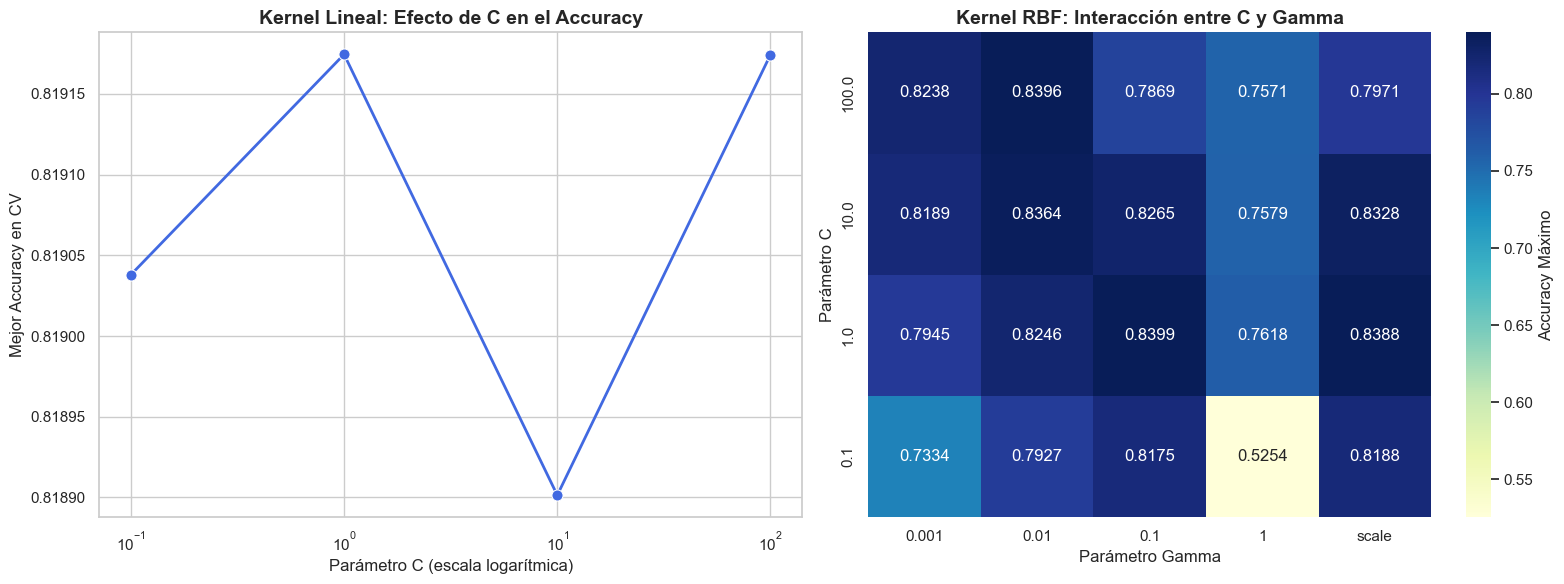

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extraemos los resultados del GridSearch a un DataFrame
resultados_df = pd.DataFrame(grid_svm.cv_results_)

# Limpiamos y preparamos las columnas
resultados_df['C'] = resultados_df['param_svc__C'].astype(float)
resultados_df['gamma'] = resultados_df['param_svc__gamma'].astype(str)
resultados_df['kernel'] = resultados_df['param_svc__kernel']
resultados_df['accuracy'] = resultados_df['mean_test_score']

# Configuración visual general
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafico 1
df_linear = resultados_df[resultados_df['kernel'] == 'linear']

# Agrupamos por C quedándonos con el mejor resultado para evitar duplicados por class_weight
df_linear_agrupado = df_linear.groupby('C')['accuracy'].max().reset_index()

sns.lineplot(
    data=df_linear_agrupado, 
    x='C', 
    y='accuracy', 
    marker='o', 
    ax=axes[0],
    color='royalblue',
    linewidth=2,
    markersize=8
)

axes[0].set_title('Kernel Lineal: Efecto de C en el Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Parámetro C (escala logarítmica)', fontsize=12)
axes[0].set_ylabel('Mejor Accuracy en CV', fontsize=12)
axes[0].set_xscale('log')

# grafico 2
df_rbf = resultados_df[resultados_df['kernel'] == 'rbf']

# Usamos pivot_table para agrupar duplicados quedándonos con el mejor accuracy
pivot_rbf = df_rbf.pivot_table(index='C', columns='gamma', values='accuracy', aggfunc='max')

# Ordenamos el índice para que las C mayores queden arriba en la gráfica
pivot_rbf = pivot_rbf.sort_index(ascending=False) 

# Dibujamos el mapa de calor
sns.heatmap(
    pivot_rbf, 
    annot=True,      
    fmt=".4f",       
    cmap="YlGnBu",   
    ax=axes[1],
    cbar_kws={'label': 'Accuracy Máximo'}
)

axes[1].set_title('Kernel RBF: Interacción entre C y Gamma', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Parámetro Gamma', fontsize=12)
axes[1].set_ylabel('Parámetro C', fontsize=12)

# Ajustamos espacios y mostramos las gráficas
plt.tight_layout()
plt.show()

Los resultados obtenidos denotan lo siguiente:

- El modelo elegido es 'rbf', ya que como se puede apreciar en las gráficas, el pico de accuracy que podemos obtener en el modelo lineal (gráfica izquierda) es casi 1.5% menor al que podemos obtener con un kernel rbf (gráfica de la derecha).

- El valor de C es muy equilibrado, 1 concretamente, por lo que el modelo permite clasificar algunos vectores mal con tal de mantener una frontera matemática capaz de generalizar muy bien.

- Gamma es también equilibrado, 0.1, lo que indica que la frontera de decisión, en rasgos generales, es bastante suave, evitando así el overfitting.

- Class Weight: None. Como era de esperar, al estar el dataset prácticamente balanceado no considera necesario aplicar un balanceado a las clases.

Estos hiperparámetros han dado como resultado un modelo con un accuracy del 83,99% el más alto hasta ahora. Sin embargo, también ha sido el modelo que con diferencia más tiempo ha costado entrenar, llegando casi a los dos minutos, algo que ninguno de los demás ha hecho, y mejorando al SVM con los hiperparámetros por defecto en solo un 0.11%, que si bien toda mejora es buena, no creemos que haya una correlación lineal entre el tiempo de entrenamiento y la mejora obtenida.

**4.3 Atributos más relevantes.**

De los dos modelos evaluados, en regresión logistica y en SVM con un kernel lineal sí se pueden obtener los atributos más relevantes, sin embargo, en un SVM con kernel no lineal (nuestro mejor modelo hasta ahora), es muy complicado obtenerlos debido al hecho que el 'kernel trick' proyecta los datos en dimensiones infinitas, destruyendo así la relación directa entre las variables originales.

Para poder hacer un correcto análisis de la importancia de caracterísitcas, se puede usar el método '.coef', que devuelve el valor absoluto de los coeficientes. Los pesos más grandes serán los que más peso tengan en la solucion final.

Para poder encontrarlos, ejecutamos el siguiente código, que consiste en una función que genera una gráfica con la importancia de las variables representada de forma visual con un gráfico de barras:

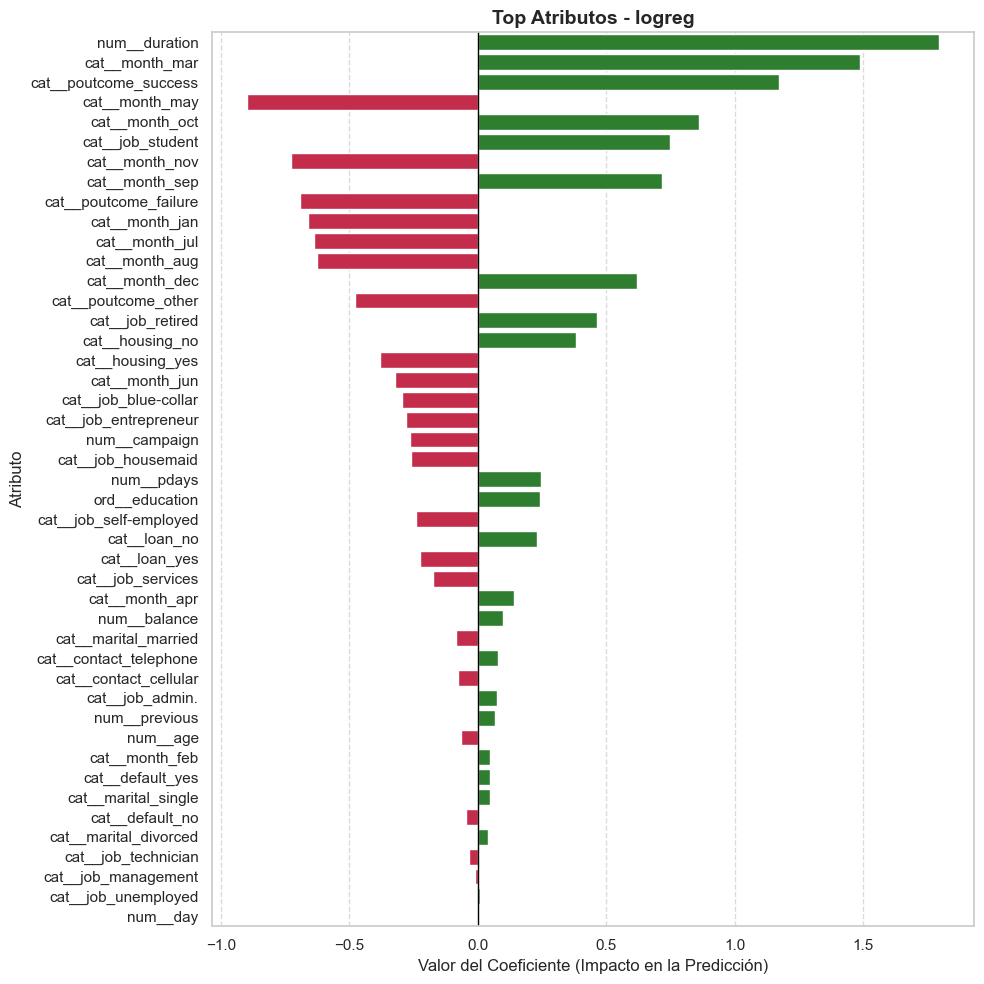

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def graficar_importancia_lineal(modelo_entrenado, nombre_paso_modelo, titulo):    
    # Extraemos las partes del pipeline
    preprocesador = modelo_entrenado.named_steps['preprocesador']
    modelo_lineal = modelo_entrenado.named_steps[nombre_paso_modelo]
    
    # Obtenemos los nombres reales de las columnas tras el preprocesado
    nombres_atributos = preprocesador.get_feature_names_out()
    
    # Extraemos los coeficientes del modelo
    coeficientes = modelo_lineal.coef_[0]
    
    # Creamos un DataFrame para manejar los datos fácilmente
    df_importancia = pd.DataFrame({
        'Atributo': nombres_atributos,
        'Coeficiente': coeficientes,
        'Importancia_Absoluta': np.abs(coeficientes) # Usamos valor absoluto para ordenar
    })
    
    # Ordenamos por el valor absoluto y nos quedamos con el Top 15 para que la gráfica sea legible
    df_top15 = df_importancia.sort_values(by='Importancia_Absoluta', ascending=False).head(50)
    
    # Generamos la gráfica
    plt.figure(figsize=(10, 10))
    
    # Usamos colores para indicar si el factor es positivo o negativo
    colores = ['forestgreen' if c > 0 else 'crimson' for c in df_top15['Coeficiente']]
    
    sns.barplot(
        data=df_top15, 
        x='Coeficiente', 
        y='Atributo', 
        palette=colores,
        hue='Atributo',
        legend=False
    )
    
    plt.title(titulo, fontsize=14, fontweight='bold')
    plt.xlabel('Valor del Coeficiente (Impacto en la Predicción)', fontsize=12)
    plt.ylabel('Atributo', fontsize=12)
    
    # Añadimos una línea vertical en el 0 para separar positivos de negativos
    plt.axvline(0, color='black', linewidth=1)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()
graficar_importancia_lineal(grid_logreg.best_estimator_, 'logreg', 'Top Atributos - logreg')

Tras analizar los resultados, observamos resultados muy interesantes:

- Si nos fijamos en las variables que más peso tienen, aparecen tres principales: num_duration, cat_poutcome_succes y cat_month_mar. Las dos primeras son lógicas hasta cierto punto, ya que si la llamada al usuario es larga, podemos deducir que él está interesado por el producto y hay más posibilidades de que se suscriba, y de la misma forma, si en anteriores ocasiones ya ha 'caído' en otras promociones, las posibilidades de que se suscriba a la que se le va a ofrecer aumentan. Sin embargo, la restante nos sorprende bastante, aunque tras investigar por nuestra cuenta, nos hemos dado cuenta, de que en efecto, marzo es el mes donde más gente se suscribe a este tipo de productos.

- Luego hay otras variables interesantes a nuestro juicio de analizar, como por ejemplo la de cat_month_may, la más fuertemente penalizada, aunque tiene sentido, ya que mayo es el mes anterior al inicio del verano y la gente tiene muchos gastos planificados. También si nos fijamos en la variable housing, el modelo deduce que es mucho más probable que un cliente suscriba un producto si no es propietario de una casa, y el mismo comportamiento se da para los clientes que tienen deudas, como se puede apreciar en la varibale loan.

## 5.Resultados y modelo final

**5.1 Seleccionar la mejor alternativa de todos los modelos**

In [56]:

# Recopilamos los resultados de la evaluación inner (best_score_) de cada GridSearchCV
resultados_inner = {
    'KNN': grid_knn.best_score_,
    'Árbol de Decisión': grid_arbol.best_score_,
    'Regresión Logística': grid_logreg.best_score_,  
    'SVM': grid_svm.best_score_
    
}

# Convertimos el diccionario a un DataFrame de Pandas para una visualización limpia
df_resultados = pd.DataFrame(list(resultados_inner.items()), columns=['Modelo', 'Accuracy (Inner CV)'])

# Ordenamos la tabla de mayor a menor rendimiento
df_resultados = df_resultados.sort_values(by='Accuracy (Inner CV)', ascending=False).reset_index(drop=True)

# Mostramos la tabla comparativa
print("--- Comparativa de Modelos (Evaluación Inner) ---")
print(df_resultados)

# Extraemos e imprimimos automáticamente el ganador
mejor_modelo_nombre = df_resultados.iloc[0]['Modelo']
mejor_accuracy = df_resultados.iloc[0]['Accuracy (Inner CV)']

print(f"\nEl modelo seleccionado como mejor alternativa es: {mejor_modelo_nombre}")
print(f"Puntuación máxima alcanzada: {mejor_accuracy:.4f}")

--- Comparativa de Modelos (Evaluación Inner) ---
                Modelo  Accuracy (Inner CV)
0                  SVM             0.839903
1    Árbol de Decisión             0.815220
2  Regresión Logística             0.813583
3                  KNN             0.805536

El modelo seleccionado como mejor alternativa es: SVM
Puntuación máxima alcanzada: 0.8399


Como era de esperar, hemos obtenido que SVM es el modelo con mayor accuracy, con un 83.99%, por lo que, omtiendo el GradientBoosting, es el mejor modelo que tenemos con diferencia (casi dos puntos de distancia respecto del siguiente), por lo que es el modelo que usaremos.

**5.2 Validación de rendimiento futuro con X_TEST e Y_TEST**

Para poder tener una idea del porcentaje de aciertos que obtendrá nuestro modelo en el futuro, lo evaluamos por primera vez con la partición TEST del Holdout. Estos datos son datos que nunca ha visto, por lo que podemos afirmar que comparar sus predicciones con ellos es un método fiable para predecir su accuracy una vez esté en producción.

--- Evaluación Outer (Conjunto de Test) ---
Modelo evaluado: SVM
Accuracy en Test: 0.8446
Precision en Test: 0.8204
Recall en Test: 0.8609
F1-Score en Test: 0.8402



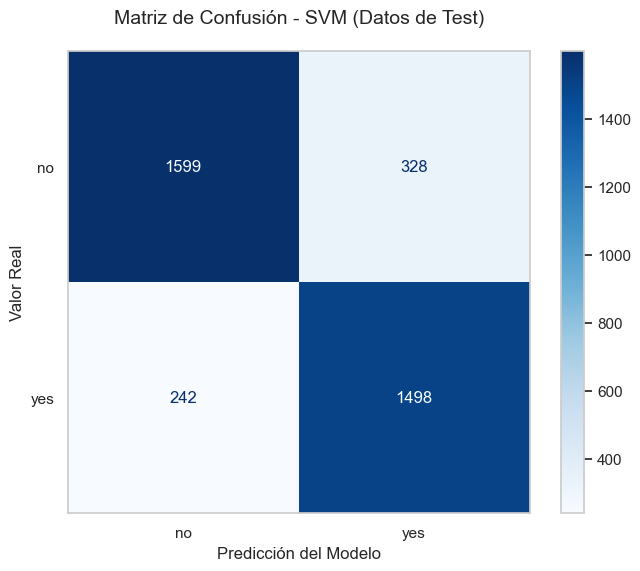

In [57]:
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Metemos el modelo con los mejores hiperparametros (entrenado con todos los datos de train) en modelo_final
modelo_final = grid_svm.best_estimator_

# Hacemos que el modelo predizca los resultados de la partición test
y_pred_test = modelo_final.predict(X_test)

# Comparamos los resultados predichos con los de verdad (y_test)
accuracy_test = metrics.accuracy_score(y_test, y_pred_test)
precision_test = metrics.precision_score(y_test, y_pred_test, pos_label='yes')
recall_test = metrics.recall_score(y_test, y_pred_test, pos_label='yes')
f1_test = metrics.f1_score(y_test, y_pred_test, pos_label='yes')

# Imprimimos las distintas metricas por pantalla
print(f"--- Evaluación Outer (Conjunto de Test) ---")
print(f"Modelo evaluado: {mejor_modelo_nombre}")
print(f"Accuracy en Test: {accuracy_test:.4f}")
print(f"Precision en Test: {precision_test:.4f}")
print(f"Recall en Test: {recall_test:.4f}")
print(f"F1-Score en Test: {f1_test:.4f}\n")

# Generamos una matríz de confusión para poder visualizar los datos mejor
cm = confusion_matrix(y_test, y_pred_test)

# Creamos la visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo_final.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d') # 'd' para mostrar números enteros


plt.title(f'Matriz de Confusión - {mejor_modelo_nombre} (Datos de Test)', pad=20, fontsize=14)
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.ylabel('Valor Real', fontsize=12)
plt.grid(False) # Quitamos la rejilla de fondo para que se vea más limpio
plt.show()

Tras evaluarlo, obtenemos un 84.46% en el accuracy, algo sorprendente, pues ha mejorado respecto al inner (83.99%), pero que tiene sentido ya que el entrenamiento en el inner se hizo solo con una parte de los datos de la partición train (había que quitar los datos de la parte de validación dentro de Train), mientras que ahora se ha entrenado con absolutamente todos los datos de train. 

Si analizamos el f1-score (84.02%), observamos que es similar al accuracy, y si nos fijamos en el Recall y en el Precision, vemos que hay una diferencia de casi cuatro puntos entre el Recall (86.09%) y el Precision (82.04%). Por lo tanto, podemos asumir que el modelo tiene una leve tendencia a ser optimista, es decir, a los casos dudosos tiene más probabilidad de clasificarlos como positivos que como negativos. Bajo nuestro punto de vista, este comportamiento es el deseado en el contexto del sector bancario, pues realizar una llamada a un cliente que no suscribirá un producto tiene un coste infinitamente menor que no llamar a uno que sí lo va a hacer.

**5.3 Entrenamiento del modelo final con todo el dataset.**

Para obtener el modelo definitivo, volvemos a hacer un entrenamiento (el último) con absolutamente todos los datos de la base de datos. Al entrenarlo con más datos que antes (le añadimos la partición test), podemos asumir que el modelo se comportará un poco mejor y superará el 84.46% de accuracy.

Una vez lo tengamos entrenado, simplemente lo guardamos en un archivo pkl.

In [58]:
import pickle
import joblib

# cogemos el modelo SVM definitivo que vamos a guardar
modelo_definitivo = grid_svm.best_estimator_

# Reentrenamos el modelo con absolutamente todos los datos, tanto x como Y y tanto train como test
modelo_definitivo.fit(X, y)
print("Modelo final entrenado.")

# Guardamos el modelo entrenado en un archivo .pkl
nombre_archivo = 'modelo_final.pkl'

# Lo guardamos en formato pickle
with open(nombre_archivo, 'wb') as archivo:
    pickle.dump(modelo_definitivo, archivo)

# Lo guardamos en formato joblib
joblib.dump(modelo_definitivo, 'modelo_final.joblib')


print("Modelo guardado exitosamente en formato .joblib")

print(f"Modelo guardado exitosamente como '{nombre_archivo}&.joblib'")

Modelo final entrenado.
Modelo guardado exitosamente en formato .joblib
Modelo guardado exitosamente como 'modelo_final.pkl&.joblib'


## 6. Tarea de elección abierta

Para la tarea de elección abierta hemos decidido entrenar un modelo ensemble, concretamente el modelo GradientBoosting, ya que queremos observar el rendimiento que este modelo nos puede brindar y compararlo con el resto de modelos.

***a) Evaluación del método con parámetros por omisión***

In [29]:
import time
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import KFold, cross_validate
from sklearn.ensemble import GradientBoostingClassifier

# Definimos las columnas según su tipo
columnas_numericas = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
columnas_ordinales = ['education']
columnas_categoricas_nominales = ['job', 'marital', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

# Pipeline numérico
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline categórico nominal
cat_pipeline = Pipeline(steps=[
    ('imputer_none', SimpleImputer(missing_values=None, strategy='most_frequent')),       
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), 
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

# Pipeline ordinal
categorias_educacion = [['primary', 'secondary', 'tertiary']] 
ord_pipeline = Pipeline(steps=[
    ('imputer_unknown', SimpleImputer(missing_values='unknown', strategy='most_frequent')), 
    ('ordinal', OrdinalEncoder(categories=categorias_educacion, handle_unknown='use_encoded_value', unknown_value=-1)),
    ('scaler', StandardScaler())
])

# Preprocesador global (ColumnTransformer)
preprocesador_gb = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, columnas_numericas),
        ('cat', cat_pipeline, columnas_categoricas_nominales),
        ('ord', ord_pipeline, columnas_ordinales)
    ], 
    remainder='drop'
)

# Pipeline final acoplado con Gradient Boosting
pipeline_gb = Pipeline(steps=[
    ('preprocesador', preprocesador_gb),
    ('gb', GradientBoostingClassifier(random_state=100522281))
])

# Definimos validación cruzada
cv_outer = KFold(n_splits=5, shuffle=True, random_state=100522281)

# Entrenamos y evaluamos
inicio = time.time()
cv_resultados_gb = cross_validate(
    pipeline_gb,
    X_train,
    y_train, 
    cv=cv_outer,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
fin = time.time()

# Resultados
accuracy_medio_gb = cv_resultados_gb['test_score'].mean()
tiempo_total_gb = fin - inicio

print(f"--- Evaluación Gradient Boosting con parámetros por defecto ---")
print(f"Accuracy medio (5 folds): {accuracy_medio_gb:.4f}")
print(f"Tiempo total del proceso: {tiempo_total_gb:.4f} segundos")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.


--- Evaluación Gradient Boosting con parámetros por defecto ---
Accuracy medio (5 folds): 0.8379
Tiempo total del proceso: 0.6828 segundos


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    0.7s finished


Tras ejecutar el código, nos sale un accuracy del 83.79%, un resultado bastante destacable, ya que solo SVM ha sacado mejores resultados, incluso sin ajustar los hiperparámetros. Además, ha tenido un tiempo de procesamiento razonablemente rápido, sin llegar al segundo, por lo que el ratio rendimiento/tiempo es extremadamente positivo.

***b) Ajuste de hiperparámetros del método***

In [30]:
from sklearn.model_selection import GridSearchCV
import time

# definimos todas las posibles combinaciones de hiperparametros+
param_grid_gb = {
    'gb__n_estimators': [100, 200, 300, 400],
    'gb__learning_rate': [0.01, 0.1, 0.2],
    'gb__max_depth': [3, 5, 7],
    'gb__subsample': [0.8, 1.0],
    'gb__min_samples_leaf': [1, 5, 7],         
    'gb__max_features': ['sqrt', None]
}

# definimos el cv
cv_inner = KFold(n_splits=5, shuffle=True, random_state=100522281)

# Configuramos gridsearch
grid_gb = GridSearchCV(
    estimator=pipeline_gb,
    param_grid=param_grid_gb,
    scoring='accuracy',
    cv=cv_inner,
    n_jobs=-1,
    verbose=1
)

# Ejecutamos la búsqueda y medimos el tiempo
print("Iniciando ajuste de hiperparámetros para Gradient Boosting...")
inicio_grid = time.time()

# Entrenamos probando todas las combinaciones
grid_gb.fit(X_train, y_train)

fin_grid = time.time()

# Calculamos y mostramos los resultados finales
print("\n--- Resultados de la Optimización (HPO) ---")
print(f"Mejor combinación de hiperparámetros:\n{grid_gb.best_params_}")
print(f"Mejor accuracy en validación cruzada: {grid_gb.best_score_:.4f}")
print(f"Tiempo total del proceso: {fin_grid - inicio_grid:.4f} segundos")

Iniciando ajuste de hiperparámetros para Gradient Boosting...
Fitting 5 folds for each of 432 candidates, totalling 2160 fits

--- Resultados de la Optimización (HPO) ---
Mejor combinación de hiperparámetros:
{'gb__learning_rate': 0.1, 'gb__max_depth': 3, 'gb__max_features': None, 'gb__min_samples_leaf': 5, 'gb__n_estimators': 400, 'gb__subsample': 0.8}
Mejor accuracy en validación cruzada: 0.8515
Tiempo total del proceso: 392.1434 segundos


Tras explorar un espacio de datos gigantesco, el modelo ha obtenido un acuraccy de un 85.16%, superando la barrera del 85% por primera vez, algo que no habíamos visto hasta ahora. Sin embargo, debido a la complejidad del modelo y al gigántesco espacio de búsqueda al que le hemos sometido, se ha gastado casi 7 minutos en encontrar los mejores hiperparámetros, algo que, si bien es asumible, ya son cifras temporales muy altas.

Para observar como afectan los distintos hiperparámetros al acuraccy implementamos el siguiente código.

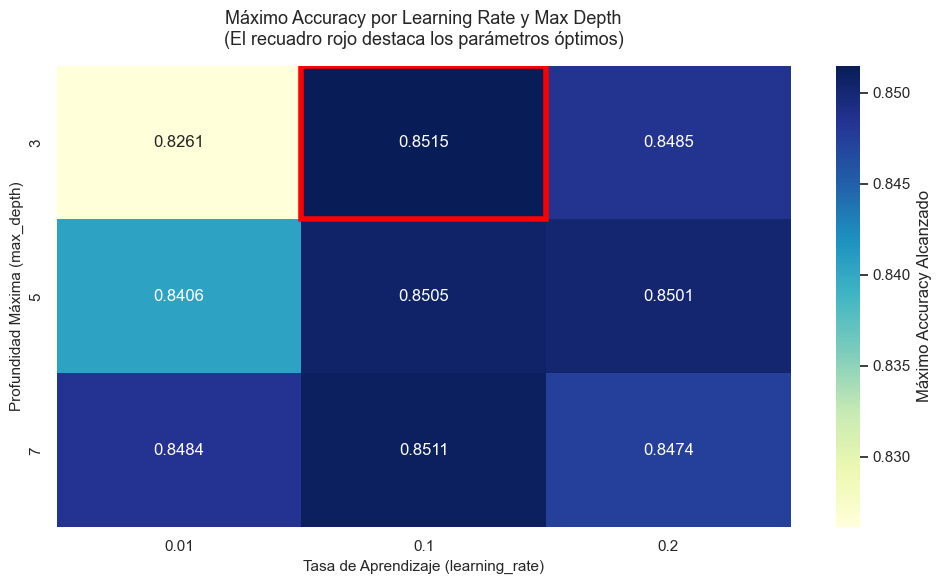

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Extraemos los resultados y limpiamos los nombres de las columnas
resultados_df = pd.DataFrame(grid_gb.cv_results_)
# Quitamos 'param_gb__' de las columnas para facilitar la lectura en pandas
resultados_df.columns = [col.replace('param_gb__', '').replace('param_', '') for col in resultados_df.columns]

# Extraemos los mejores parámetros directamente del modelo
mejor_score = grid_gb.best_score_
mejores_params = grid_gb.best_params_

mejor_n_estimators = mejores_params['gb__n_estimators']
mejor_learning_rate = mejores_params['gb__learning_rate']
mejor_max_depth = mejores_params['gb__max_depth']

# Agrupamos quedándonos con el 'max' accuracy para cada par (colapsamos otras dimensiones)
pivot_table = resultados_df.pivot_table(
    index='max_depth', 
    columns='learning_rate', 
    values='mean_test_score',
    aggfunc='max'
)

plt.figure(figsize=(10, 6))
ax = sns.heatmap(pivot_table, annot=True, cmap='YlGnBu', fmt='.4f', 
                 cbar_kws={'label': 'Máximo Accuracy Alcanzado'})

# Lógica para encontrar las coordenadas (x, y) de la mejor combinación en la tabla pivotada
mejor_lr_idx = list(pivot_table.columns).index(mejor_learning_rate)
mejor_md_idx = list(pivot_table.index).index(mejor_max_depth)

# Dibujamos un recuadro rojo llamativo alrededor de la celda ganadora
import matplotlib.patches as patches
ax.add_patch(
    patches.Rectangle(
        (mejor_lr_idx, mejor_md_idx), # Coordenada esquina inferior izquierda
        1, 1,                         # Ancho y alto de 1 celda
        fill=False,                   # Sin relleno para que se vea el número
        edgecolor='red',              # Color del borde
        lw=4                          # Grosor de la línea
    )
)

plt.title('Máximo Accuracy por Learning Rate y Max Depth\n(El recuadro rojo destaca los parámetros óptimos)', fontsize=13, pad=15)
plt.ylabel('Profundidad Máxima (max_depth)', fontsize=11)
plt.xlabel('Tasa de Aprendizaje (learning_rate)', fontsize=11)
plt.tight_layout()
plt.show()

Tras analizar la gráfica, nos damos cuenta que si analizamos los hiperparámetros elegidos, el modelo ha hecho todo lo posible por evitar memorizar el ruido de los datos e introducir aleatoriedad. Esto es porque:

- max_features: 'sqrt' y subsample: 0.8: En lugar de usar todos los datos, el modelo prefirió "cegarse" en cada árbol, utilizando solo una fracción aleatoria de las columnas y de los clientes. Esto reduce drásticamente la varianza.

- max_depth: 5 y min_samples_leaf: 5: El modelo permitió construir árboles un poco más profundos que el estándar, y lo compensó exigiendo al menos 5 clientes en cada hoja terminal para no crear reglas exclusivas para casos aislados.

- n_estimators: 300 y learning_rate: 0.1: Al tener tantas trabas para aprender (por culpa del sqrt y el subsample), el algoritmo compensó necesitando construir una secuencia más larga de árboles (300) a un ritmo constante para estabilizar la predicción.

Por lo tanto, tras entrenarlo y analizar sus resultados, podemos asumir que estamos ante el modelo más potente y que mejor generaliza de todos los que hemos preobado en esta práctica.

**Declaración de uso de IA**

En este cuaderno, la IA se utilizó principalmente en:

- Al hacer el EDA, ya que nos veíamos en la necesidad de usar funciones de pandas que no conocíamos, por lo que recurrimos a la inteligencia artificial.

- En KNN, recurrimos a ella para hacer el primer preprocesado del dataset, ya que no sabíamos como empezar. 

- Hemos empleado la IA para realizar ciertas partes del desarrollo de las gráficas de este notebook. 

- Nos hemos ayudado de la IA para realizar el script de Python de streamlit.

Ejemplo de prompt que hemos utilizado: 
Realiza porfavor una modificación al código de la generación del gráfico de KNN para que sean dos gráficos, uno al lado de otro, donde el de la derecha tenga “zoom” en el punto de accuracy más alto para ver con mejor claridad la diferencia con los derecha alrededor